Copied from polarizationAlignment_EB_25JUNE25, to compare Gammas 

In [1]:
## IMPORTS
import numpy as np
import os
import tifffile
from sklearn.cluster import KMeans
import matplotlib as mpl
import matplotlib.pyplot as plt
import cv2
#from tqdm import tqdm
from scipy.fft import fftn, ifftn
from scipy.ndimage import fourier_shift, gaussian_filter
from scipy.ndimage import shift as img_shift
from numpy.fft import fftshift
from scipy.signal import find_peaks, peak_widths
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit


from skimage.feature import graycomatrix, graycoprops
from skimage import io

%matplotlib inline
from ipywidgets import interact, IntSlider


In [2]:
## FUNCTIONS

def calc_NRMSE(input_array, ref_array):
    NRMSE = (np.sqrt(np.mean((ref_array - input_array)**2)))/(np.max(ref_array) - np.min(ref_array))     
    return NRMSE

def auto_normalize_by_fiducial(image, c, bins=100, peak_prominence=0.0001, window_width=0.1, plot_hist=True):
    """
    Automatically detects the high-intensity fiducial peak and normalizes image by its average.
    Use on non processed CPL images, not XMCD or CC

    Parameters:
    - image: 2D numpy array
    - bins: number of histogram bins
    - peak_prominence: sensitivity of peak detection
    - window_width: +/- width around second peak (in normalized intensity units)
    - plot_hist: whether to show histogram

    Returns:
    - normalized_image: image divided by fiducial average
    - fiducial_mean: average intensity used for normalization
    """
    
    # print('Use on non processed CPL images, not XMCD or CC')
    flat = image.flatten()
    hist_vals, bin_edges = np.histogram(flat, bins=bins, density=True)
    smoothed = gaussian_filter1d(hist_vals, sigma=1) #2
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Find peaks in smoothed histogram
    peaks, props = find_peaks(smoothed, prominence=peak_prominence)

    if len(peaks) < 2:
        raise ValueError("Could not find at least two peaks in histogram.")

    # Assume the right-most peak is the fiducial
    fid_peak_idx = peaks[np.argmax(bin_centers[peaks])]
    fid_peak_center = bin_centers[fid_peak_idx]

    # Define intensity range around this peak
    range_min = fid_peak_center - window_width
    range_max = fid_peak_center + window_width

    # Extract pixels in this intensity window
    mask = (flat >= range_min) & (flat <= range_max)
    fiducial_vals = flat[mask]

    if fiducial_vals.size == 0:
        raise ValueError("No pixels found in automatically selected fiducial range.")

    fiducial_mean = np.mean(fiducial_vals)
    normalized_image = image / fiducial_mean

    if plot_hist == True:
        plt.figure(figsize=(8,4))
        plt.plot(bin_centers, hist_vals, label='Histogram', alpha=0.3)
        plt.plot(bin_centers, smoothed, label='Smoothed Histogram', color='black')
        plt.axvline(range_min, color= c, linestyle='--', label='Range min')
        plt.axvline(range_max, color= c, linestyle='--', label='Range max')
        plt.axvline(fid_peak_center, color='red', linestyle='--', label=f'Fiducial peak = {fid_peak_center}')
        plt.title("Histogram and Fiducial Detection")
        plt.xlabel("Intensity")
        plt.ylabel("Density")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return normalized_image, fiducial_mean


def auto_normalize_by_fiducial_log_FWHM(
    image, c, hist_color, bins=100,
    peak_prominence=0.01, window_width=0.1,
    window_width_CC=0.3, plot_hist=True
):
    '''
    Use this if you have a non-nan image
    '''
    #print('USE THIS FUNCTION WHEN THE IMAGE HAS BEEN NORMALIZED BY OPTICAL DENSITY ')
    flat = image.flatten()
    hist_vals, bin_edges = np.histogram(flat, bins=bins, density=True)
    smoothed = gaussian_filter1d(hist_vals, sigma=1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Find peaks
    peaks, props = find_peaks(smoothed, prominence=peak_prominence)
    if len(peaks) < 1:
        raise ValueError("No peaks found in histogram.")
    
    peak_centers = bin_centers[peaks]

    # Fiducial = left-most, CC = right-most
    fid_idx = np.argmin(peak_centers)
    CC_idx = np.argmax(peak_centers)
    fid_peak_center = peak_centers[fid_idx]
    CC_peak_center = peak_centers[CC_idx]

    # FWHM of peaks
    results_half = peak_widths(smoothed, peaks, rel_height=0.5)
    widths = results_half[0] * (bin_centers[1] - bin_centers[0])  # convert index width → x-units
    fid_FWHM = widths[fid_idx]
    CC_FWHM = widths[CC_idx]

    # CC normalization
    CC_range_min, CC_range_max = CC_peak_center - window_width_CC, CC_peak_center + window_width_CC
    mask = (flat >= CC_range_min) & (flat <= CC_range_max)
    CC_vals = flat[mask]

    if CC_vals.size == 0:
        raise ValueError("No pixels found in automatically selected CC range.")

    CC_mean = np.mean(CC_vals)
    # print(f'CC mean in range = {CC_mean}')
    normalized_CC = image / CC_mean
    scale = 1 / CC_peak_center
    # print(f'scale = {scale}')

    if plot_hist:
        plt.figure(figsize=(8,4))
        plt.plot(bin_centers, hist_vals, label='Histogram', alpha=0.3)
        plt.plot(bin_centers, smoothed, label='Smoothed Histogram', color='black')
        
        plt.axvline(fid_peak_center, color='red', linestyle='--', label=f"Fid Peak = {fid_peak_center:.2f}")
        plt.axvline(CC_peak_center, color='pink', linestyle='--', label=f"CC Peak = {CC_peak_center:.2f}")
        
        plt.title("Histogram and Peak Detection")
        plt.xlabel("Intensity")
        plt.ylabel("Density")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return normalized_CC, CC_mean, CC_peak_center, fid_peak_center, CC_FWHM, fid_FWHM

def auto_normalize_by_fiducial_log_FWHM_nan(
    image, c, hist_color, bins=100,
    peak_prominence=0.01, window_width=0.1,
    window_width_CC=0.3, plot_hist=True
):
    # Flatten and drop NaNs/Infs
    flat = image.flatten()
    flat = flat[np.isfinite(flat)]

    if flat.size == 0:
        raise ValueError("Image contains only NaN/Inf values, cannot normalize.")

    # Histogram on finite pixels only
    hist_vals, bin_edges = np.histogram(flat, bins=bins, density=True)
    smoothed = gaussian_filter1d(hist_vals, sigma=1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Find peaks
    peaks, props = find_peaks(smoothed, prominence=peak_prominence)
    if len(peaks) < 1:
        raise ValueError("No peaks found in histogram.")
    
    peak_centers = bin_centers[peaks]

    # Fiducial = left-most, CC = right-most
    fid_idx = np.argmin(peak_centers)
    CC_idx = np.argmax(peak_centers)
    fid_peak_center = peak_centers[fid_idx]
    CC_peak_center = peak_centers[CC_idx]

    # FWHM of peaks
    results_half = peak_widths(smoothed, peaks, rel_height=0.5)
    widths = results_half[0] * (bin_centers[1] - bin_centers[0])  # index width → x-units
    fid_FWHM = widths[fid_idx]
    CC_FWHM = widths[CC_idx]

    # CC normalization (still on finite values)
    CC_range_min, CC_range_max = CC_peak_center - window_width_CC, CC_peak_center + window_width_CC
    mask = (flat >= CC_range_min) & (flat <= CC_range_max)
    CC_vals = flat[mask]

    if CC_vals.size == 0:
        raise ValueError("No pixels found in automatically selected CC range.")

    CC_mean = np.mean(CC_vals)
    normalized_CC = image / CC_mean   # preserves NaNs
    scale = 1 / CC_peak_center

    if plot_hist:
        plt.figure(figsize=(5,4))
        plt.plot(bin_centers, hist_vals, label='Histogram', alpha=0.3)
        plt.plot(bin_centers, smoothed, label='Smoothed Histogram', color='black')
        
        plt.axvline(fid_peak_center, color='red', linestyle='--', label=f"Fid Peak = {fid_peak_center:.2f}")
        plt.axvline(CC_peak_center, color='pink', linestyle='--', label=f"CC Peak = {CC_peak_center:.2f}")
        
        plt.title("Histogram and Peak Detection")
        plt.xlabel("Intensity")
        plt.ylabel("Density")
        plt.legend()
        plt.tight_layout()
        plt.show()

        # Compare histograms ignoring NaNs again
        plt.hist(image[np.isfinite(image)].flatten(), bins=100, alpha=0.4, color=hist_color, label='Pre-Scale')
        plt.hist(normalized_CC[np.isfinite(normalized_CC)].flatten(), bins=100, alpha=0.8, color=hist_color, label=f'Post-Scale = {scale:.2f}')
        plt.xlabel('Intensity')
        plt.ylabel('Pixel Count')
        plt.legend()
        plt.title('Normalized & Aligned CC (FWHM)')
        plt.show()

    return normalized_CC, CC_mean, CC_peak_center, fid_peak_center, CC_FWHM, fid_FWHM




def gaussian(x, A, mu, sigma):
    return A * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2))

def auto_normalize_by_fiducial_log_FWHM_nan_area(
    image, c, hist_color, bins=100,
    peak_prominence=0.01, window_width=0.1,
    window_width_CC=0.3, plot_hist=True
):
    # Flatten and drop NaNs/Infs
    flat = image.flatten()
    flat = flat[np.isfinite(flat)]

    if flat.size == 0:
        raise ValueError("Image contains only NaN/Inf values, cannot normalize.")

    # Histogram on finite pixels only
    hist_vals, bin_edges = np.histogram(flat, bins=bins, density=True)
    smoothed = gaussian_filter1d(hist_vals, sigma=1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Find peaks
    peaks, props = find_peaks(smoothed, prominence=peak_prominence)
    if len(peaks) < 1:
        raise ValueError("No peaks found in histogram.")
    
    peak_centers = bin_centers[peaks]

    # Fiducial = left-most, CC = right-most
    fid_idx = np.argmin(peak_centers)
    CC_idx = np.argmax(peak_centers)
    fid_peak_center = peak_centers[fid_idx]
    CC_peak_center = peak_centers[CC_idx]

    # FWHM of peaks
    results_half = peak_widths(smoothed, peaks, rel_height=0.5)
    widths = results_half[0] * (bin_centers[1] - bin_centers[0])  # index width → x-units
    fid_FWHM = widths[fid_idx]
    CC_FWHM = widths[CC_idx]

    # CC normalization (still on finite values)
    CC_range_min, CC_range_max = CC_peak_center - window_width_CC, CC_peak_center + window_width_CC
    mask = (flat >= CC_range_min) & (flat <= CC_range_max)
    CC_vals = flat[mask]

    if CC_vals.size == 0:
        raise ValueError("No pixels found in automatically selected CC range.")

    CC_mean = np.mean(CC_vals)
    normalized_CC = image / CC_mean   # preserves NaNs
    scale = 1 / CC_peak_center

    # --- Gaussian Fit to CC peak for Area ---
    # restrict to region around CC peak for stability
    fit_mask = (bin_centers >= CC_range_min) & (bin_centers <= CC_range_max)
    x_fit = bin_centers[fit_mask]
    y_fit = smoothed[fit_mask]

    try:
        p0 = [np.max(y_fit), CC_peak_center, CC_FWHM / 2.355]  # initial guess
        popt, _ = curve_fit(gaussian, x_fit, y_fit, p0=p0)
        A_fit, mu_fit, sigma_fit = popt
        area_gaussian = A_fit * sigma_fit * np.sqrt(2 * np.pi)
    except RuntimeError:
        A_fit, mu_fit, sigma_fit, area_gaussian = np.nan, np.nan, np.nan, np.nan

    if plot_hist:
        plt.figure(figsize=(8,4))
        plt.plot(bin_centers, hist_vals, label='Histogram', alpha=0.3)
        plt.plot(bin_centers, smoothed, label='Smoothed Histogram', color='black')
        plt.axvline(fid_peak_center, color='red', linestyle='--', label=f"Fid Peak = {fid_peak_center:.2f}")
        plt.axvline(CC_peak_center, color='pink', linestyle='--', label=f"CC Peak = {CC_peak_center:.2f}")
        # plot fitted Gaussian
        if not np.isnan(area_gaussian):
            plt.plot(x_fit, gaussian(x_fit, *popt), 'g--', label=f'Gaussian Fit (Area={area_gaussian:.2f})')
        plt.title("Histogram and Peak Detection")
        plt.xlabel("Intensity")
        plt.ylabel("Density")
        plt.legend()
        plt.tight_layout()
        plt.show()

        # Compare histograms ignoring NaNs again
        plt.hist(image[np.isfinite(image)].flatten(), bins=100, alpha=0.4, color=hist_color, label='Pre-Scale')
        plt.hist(normalized_CC[np.isfinite(normalized_CC)].flatten(), bins=100, alpha=0.8, color=hist_color, label=f'Post-Scale = {scale:.2f}')
        plt.xlabel('Intensity')
        plt.ylabel('Pixel Count')
        plt.legend()
        plt.title('Normalized & Aligned CC (FWHM)')
        plt.show()

    return (normalized_CC, CC_mean, CC_peak_center, fid_peak_center,
            CC_FWHM, fid_FWHM, area_gaussian, (A_fit, mu_fit, sigma_fit))




def normalize_CC1(
    image, c, hist_color, bins=100,
    peak_prominence=0.01, window_width=0.1,
    window_width_CC=0.3, plot_hist=True
):
    # Flatten and drop NaNs/Infs
    flat = image.flatten()
    flat = flat[np.isfinite(flat)]

    if flat.size == 0:
        raise ValueError("Image contains only NaN/Inf values, cannot normalize.")

    # Histogram on finite pixels only
    hist_vals, bin_edges = np.histogram(flat, bins=bins, density=True)
    smoothed = gaussian_filter1d(hist_vals, sigma=1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Find peaks
    peaks, props = find_peaks(smoothed, prominence=peak_prominence)
    if len(peaks) < 1:
        raise ValueError("No peaks found in histogram.")
    
    peak_centers = bin_centers[peaks]

    # Fiducial = left-most, CC = right-most
    fid_idx = np.argmin(peak_centers)
    CC_idx = np.argmax(peak_centers)
    fid_peak_center = peak_centers[fid_idx]
    CC_peak_center = peak_centers[CC_idx]

    # FWHM of peaks
    results_half = peak_widths(smoothed, peaks, rel_height=0.5)
    widths = results_half[0] * (bin_centers[1] - bin_centers[0])  # index width → x-units
    fid_FWHM = widths[fid_idx]
    CC_FWHM = widths[CC_idx]

    # CC normalization (still on finite values)
    CC_range_min, CC_range_max = CC_peak_center - window_width_CC, CC_peak_center + window_width_CC
    mask = (flat >= CC_range_min) & (flat <= CC_range_max)
    CC_vals = flat[mask]

    if CC_vals.size == 0:
        raise ValueError("No pixels found in automatically selected CC range.")

    CC_mean = np.mean(CC_vals)
    normalized_CC = image / CC_mean   # shift CC peak to ~1
    scale_center = 1 / CC_peak_center

    # --- Gaussian Fit to CC peak for Area ---
    fit_mask = (bin_centers >= CC_range_min) & (bin_centers <= CC_range_max)
    x_fit = bin_centers[fit_mask]
    y_fit = smoothed[fit_mask]

    try:
        p0 = [np.max(y_fit), CC_peak_center, CC_FWHM / 2.355]  # initial guess
        popt, _ = curve_fit(gaussian, x_fit, y_fit, p0=p0)
        A_fit, mu_fit, sigma_fit = popt
        area_gaussian = A_fit * sigma_fit * np.sqrt(2 * np.pi)
    except RuntimeError:
        A_fit, mu_fit, sigma_fit, area_gaussian = np.nan, np.nan, np.nan, np.nan

    # --- Area normalization step ---
    if not np.isnan(area_gaussian) and area_gaussian > 0:
        normalized_CC = normalized_CC / area_gaussian
        area_norm_factor = 1 / area_gaussian
    else:
        area_norm_factor = np.nan

    if plot_hist:
        plt.figure(figsize=(5,4))
        plt.plot(bin_centers, hist_vals, label='Histogram', alpha=0.3)
        plt.plot(bin_centers, smoothed, label='Smoothed Histogram', color='black')
        plt.axvline(fid_peak_center, color='red', linestyle='--', label=f"Fid Peak = {fid_peak_center:.2f}")
        plt.axvline(CC_peak_center, color='pink', linestyle='--', label=f"CC Peak = {CC_peak_center:.2f}")
        # plot fitted Gaussian
        if not np.isnan(area_gaussian):
            plt.plot(x_fit, gaussian(x_fit, *popt), 'g--',
                     label=f'Gaussian Fit (Area={area_gaussian:.2f})')
        plt.title("Gaussian fit of fiducial and CC Peaks")
        plt.xlabel("Intensity")
        plt.ylabel("Density")
        plt.legend()
        plt.tight_layout()
        plt.show()

        # Compare histograms ignoring NaNs again
        plt.hist(image[np.isfinite(image)].flatten(), bins=100, alpha=0.4, color=hist_color, label='Pre-Scale')
        plt.hist(normalized_CC[np.isfinite(normalized_CC)].flatten(), bins=100, alpha=0.8, color=hist_color,
                 label=f'Post-Scale Center= {scale_center:.2f}, AreaNorm={area_norm_factor:.2f}')
        plt.xlabel('Intensity')
        plt.ylabel('Pixel Count')
        plt.legend()
        plt.title('Normalized & Aligned CC (Center + Area)')
        plt.show()

    return (normalized_CC, CC_mean, CC_peak_center, fid_peak_center,
            CC_FWHM, fid_FWHM, area_gaussian, area_norm_factor,
            (A_fit, mu_fit, sigma_fit))





# Loading Projection Data

In [3]:
#### n = 50
sample = "665"
Gamma= "Gammaneg45"
date = '_5AUG25_check_saturation_n50'
date1 = date

data_dir = f"RawData/{sample}/{Gamma}"

pos_images = f"OD_pospol_stack{date}.tiff"
pos_angles_neg45 = f"angles_pospol{date1}.txt" #### angles are adjusted in ptychoMatFile_toTIFF
neg_images = f"OD_negpol_stack{date}.tiff"
# neg_angles = f"angles_negpol{date1}.txt"  #### angles are adjusted in ptychoMatFile_toTIFF
angles = f"angles_shifted{date1}.txt"   ##### angles shifted to the real alpha = 0
# CC = f"OD_chrgcntrst_stack{date1}.tiff"
# XMCD = f"OD_XMCD_stack{date1}.tiff"
CC = f"Gamma_alpha_aligned_CC{date1}_full_forDinesh_nan.tiff" ## mirrored and inverted in Gamma_Alpha_Alignment
XMCD = f"Gamma_alpha_aligned_XMCD{date1}_full_forDinesh_nan.tiff" ## mirrored and inverted in Gamma_Alpha_Alignment

image_stack_pospol_neg45 = tifffile.imread(os.path.join(data_dir, pos_images)) #[:, ::-1, :] *-1
image_stack_negpol_neg45 = tifffile.imread(os.path.join(data_dir, neg_images)) #[:, ::-1, :] *-1
CC_neg45 = tifffile.imread(os.path.join(data_dir, CC))
XMCD_neg45 = tifffile.imread(os.path.join(data_dir, XMCD))
angles_neg45 = np.loadtxt(os.path.join(data_dir, angles))
# print(angles_neg45.shape)
# print(XMCD_neg45.shape)

## mirror and invert neg45
# CC_neg45 =  CC_neg45_mirror[:, ::-1, :] 
# XMCD_neg45 = XMCD_neg45_mirror[:, ::-1, :] *-1


Gamma= "Gammapos45"
date = '_5AUG25_check_saturation_n50'
date1 = date

data_dir = f"RawData/{sample}/{Gamma}"

pos_images = f"OD_pospol_stack{date}.tiff"
# pos_angles_pos45 = f"angles_pospol{date1}.txt" #### angles are adjusted in ptychoMatFile_toTIFF
neg_images = f"OD_negpol_stack{date}.tiff"
# neg_angles = f"angles_negpol{date1}.txt"  #### angles are adjusted in ptychoMatFile_toTIFF
angles = f"angles_shifted{date1}.txt"   ##### angles shifted to the real alpha = 0
CC = f"OD_chrgcntrst_stack{date1}.tiff"
XMCD = f"OD_XMCD_stack{date1}.tiff"


image_stack_pospol_pos45 = tifffile.imread(os.path.join(data_dir, pos_images))
image_stack_negpol_pos45 = tifffile.imread(os.path.join(data_dir, neg_images))
CC_pos45 = tifffile.imread(os.path.join(data_dir, CC))
XMCD_pos45 = tifffile.imread(os.path.join(data_dir, XMCD))
angles_pos45 = np.loadtxt(os.path.join(data_dir, angles))
# print(angles_pos45.shape)
# print(XMCD_pos45.shape)


Gamma= "Gamma0"
date = '_3AUG25_check_saturation_n50'
date1 = date

data_dir = f"RawData/{sample}/{Gamma}"

pos_images = f"OD_pospol_stack{date}.tiff"
pos_angles_0 = f"angles_pospol{date1}.txt" #### angles are adjusted in ptychoMatFile_toTIFF
neg_images = f"OD_negpol_stack{date}.tiff"
# neg_angles = f"angles_negpol{date1}.txt"  #### angles are adjusted in ptychoMatFile_toTIFF
angles = f"angles_shifted{date1}.txt"   ##### angles shifted to the real alpha = 0
CC = f"Gamma_alpha_aligned_CC{date1}_full_forDinesh_nan.tiff" 
XMCD = f"Gamma_alpha_aligned_XMCD{date1}_full_forDinesh_nan.tiff" 


image_stack_pospol_0 = tifffile.imread(os.path.join(data_dir, pos_images))
image_stack_negpol_0 = tifffile.imread(os.path.join(data_dir, neg_images))
CC_0 = tifffile.imread(os.path.join(data_dir, CC))
XMCD_0 = tifffile.imread(os.path.join(data_dir, XMCD))
angles_0 = np.loadtxt(os.path.join(data_dir, angles))
# print(angles_0.shape)
# print(XMCD_0.shape)



In [4]:
#### n = 20 

# Gamma= "Gammaneg45"
# date = '_5AUG25_check_saturation_n50'
# date1 = date

# data_dir = f"RawData/{sample}/{Gamma}"

# pos_images = f"OD_pospol_stack{date}.tiff"
# pos_angles_neg45 = f"angles_pospol{date1}.txt" #### angles are adjusted in ptychoMatFile_toTIFF
# neg_images = f"OD_negpol_stack{date}.tiff"
# neg_angles = f"angles_negpol{date1}.txt"  #### angles are adjusted in ptychoMatFile_toTIFF
# CC = f"OD_chrgcntrst_stack{date1}.tiff"
# XMCD = f"OD_XMCD_stack{date1}.tiff"

# image_stack_pospol_neg45 = tifffile.imread(os.path.join(data_dir, pos_images))
# image_stack_negpol_neg45 = tifffile.imread(os.path.join(data_dir, neg_images))
# CC_neg45 = tifffile.imread(os.path.join(data_dir, CC))
# XMCD_neg45 = tifffile.imread(os.path.join(data_dir, XMCD))
# pos_angles_neg45 = np.loadtxt(os.path.join(data_dir, pos_angles_neg45))



# Gamma= "Gammapos45"
# date = '_17JUNE25_EB_n20all_fixedlog'
# date1 = '_17JUNE25_EB_n20all'

# data_dir = f"RawData/{sample}/{Gamma}"

# pos_images = f"OD_pospol_stack{date1}.tiff"
# pos_angles = f"angles_pospol{date1}.txt" #### angles are adjusted in ptychoMatFile_toTIFF
# neg_images = f"OD_negpol_stack{date1}.tiff"
# neg_angles = f"angles_negpol{date1}.txt"  #### angles are adjusted in ptychoMatFile_toTIFF
# CC = f"OD_chrgcntrst_stack{date}.tiff"
# XMCD = f"OD_XMCD_stack{date}.tiff"

# image_stack_pospol_pos45_20 = tifffile.imread(os.path.join(data_dir, pos_images))
# image_stack_negpol_pos45_20 = tifffile.imread(os.path.join(data_dir, neg_images))
# CC_pos45_20 = tifffile.imread(os.path.join(data_dir, CC))
# XMCD_pos45_20 = tifffile.imread(os.path.join(data_dir, XMCD))
# pos_angles_pos45_20 = np.loadtxt(os.path.join(data_dir, pos_angles))


# Gamma= "Gamma0"
# date = '_20JUNE25_EB_n20all_fixedlog'
# date1 = '_20JUNE25_EB_n20all'

# data_dir = f"RawData/{sample}/{Gamma}"

# pos_images = f"OD_pospol_stack{date1}.tiff"
# pos_angles = f"angles_pospol{date1}.txt" #### angles are adjusted in ptychoMatFile_toTIFF
# neg_images = f"OD_negpol_stack{date1}.tiff"
# neg_angles = f"angles_negpol{date1}.txt"  #### angles are adjusted in ptychoMatFile_toTIFF
# CC = f"OD_chrgcntrst_stack{date}.tiff"
# XMCD = f"OD_XMCD_stack{date}.tiff"

# image_stack_pospol_0_20 = tifffile.imread(os.path.join(data_dir, pos_images))
# image_stack_negpol_0_20 = tifffile.imread(os.path.join(data_dir, neg_images))
# CC_0_20 = tifffile.imread(os.path.join(data_dir, CC))
# XMCD_0_20 = tifffile.imread(os.path.join(data_dir, XMCD))
# pos_angles_0_20= np.loadtxt(os.path.join(data_dir, pos_angles))

# Compare un-scaled Γ=0 and -45

38.923351984


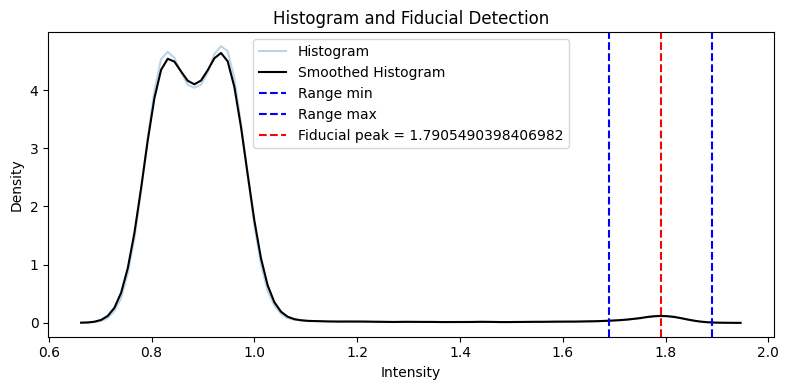

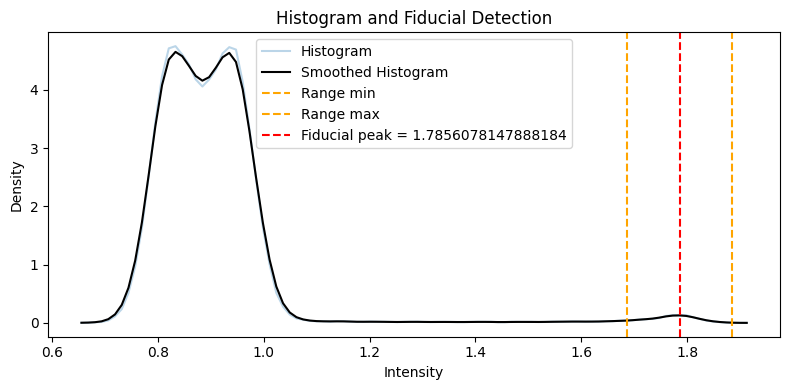

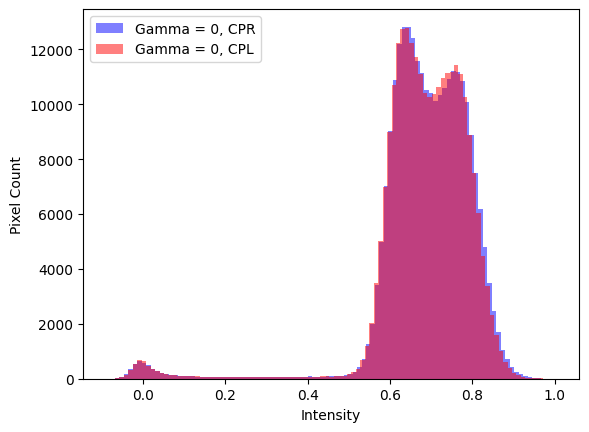

38.92237324800001


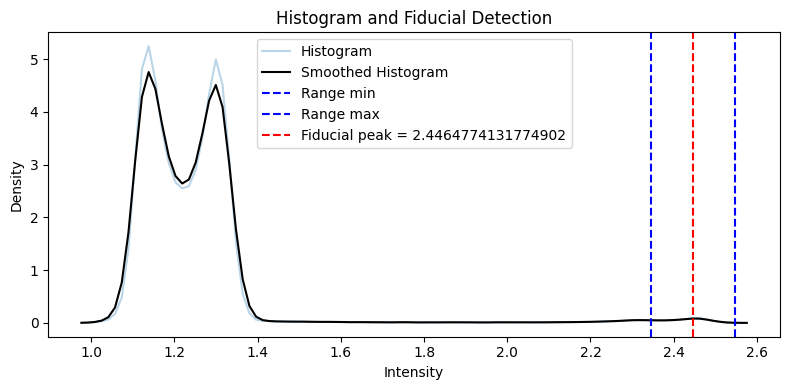

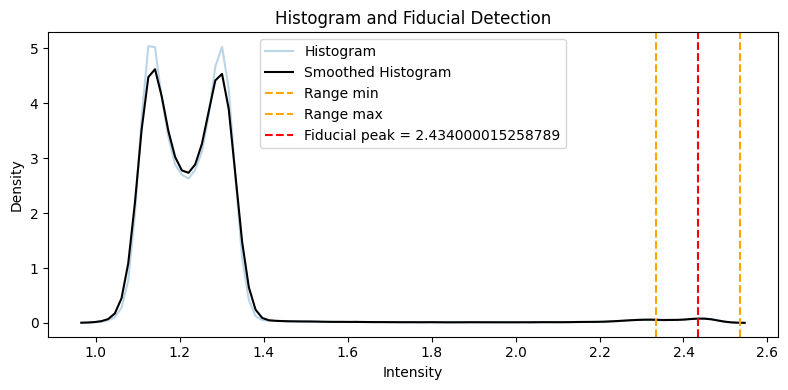

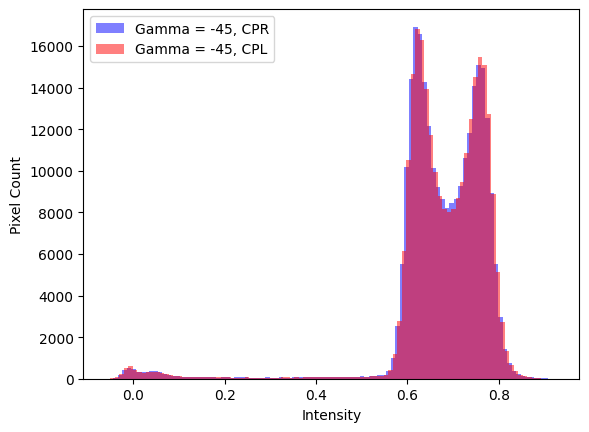

In [5]:
## Plot CPL and CPR, pre and post optical density transformation
color_neg = 'blue'
color_pos = 'orange'

norm = mpl.colors.Normalize(vmin=-0.2, vmax=0.2)

# ############### Gamma pos45
# k = 60
# angle = angles_pos45[k]
# # print(angle)

# ## normalize left and right to average intensity of the fiducials 
# norm_neg_pos45, fid_avg_neg = auto_normalize_by_fiducial(image_stack_pospol_pos45[k], color_neg)
# norm_pos_pos45, fid_avg_pos = auto_normalize_by_fiducial(image_stack_negpol_pos45[k], color_pos)

# # transition everything to OD
# OD_img_pos_pos45 = -1*np.log(norm_pos_pos45)
# OD_img_neg_pos45= -1*np.log(norm_neg_pos45)
                                                         
# norm_CC_pos45 = CC_pos45[k]
# norm_XMCD_pos45 = XMCD_pos45[k]

# ## Plot XMCD to see contrast a bit better, control norm above
# fig_size = 3.5
# fig, axes = plt.subplots(1, 1, figsize=(fig_size * 3, fig_size))
# pos = axes.imshow(norm_XMCD_pos45, norm=norm)
# axes.set_title(f"Gamma +45 @ {angle:.2f}") 
# fig.colorbar(pos)
# plt.show()


# ## Plot CPL
# vals_CC_neg45 = image_stack_pospol_pos45[k].flatten()
# vals_CC_neg45_left = image_stack_negpol_pos45[k].flatten()

# plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'blue', label = 'Gamma = +45, CPR')
# plt.hist(vals_CC_neg45_left, bins = 100, alpha = 0.5, color = 'red', label = 'Gamma = +45, CPL')

# plt.xlabel('Intensity')
# plt.ylabel('Pixel Count')
# # plt.xlim(-0.25, 0.25)
# # plt.ylim(0, 1500)
# plt.legend()
# plt.show()



############ Gamma 0
k0 = 90
angle = angles_0[k0]
print(angle)

## normalize left and right to average intensity of the fiducials 
norm_neg_0, fid_avg_neg = auto_normalize_by_fiducial(image_stack_negpol_0[k0], color_neg)
norm_pos_0, fid_avg_pos = auto_normalize_by_fiducial(image_stack_pospol_0[k0], color_pos)

OD_img_pos_0 = -1*np.log(norm_neg_0)
OD_img_neg_0 = -1*np.log(norm_pos_0)

norm_CC_0 = CC_0[k0]
norm_XMCD_0 = XMCD_0[k0]

# ## Plot XMCD to see contrast a bit better, control norm above
# fig_size = 3.5
# fig, axes = plt.subplots(1, 1, figsize=(fig_size * 3, fig_size))
# pos = axes.imshow(XMCD_0[k0], norm=norm)
# axes.set_title(f"Gamma 0 @ {angle:.2f}") 
# fig.colorbar(pos)
# plt.show()

## Plot CPL
vals_CC_neg45 = OD_img_pos_0.flatten()
vals_CC_neg45_left = OD_img_neg_0.flatten()

plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'blue', label = 'Gamma = 0, CPR')
plt.hist(vals_CC_neg45_left, bins = 100, alpha = 0.5, color = 'red', label = 'Gamma = 0, CPL')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.show()


############### Gamma neg45
kneg45 = 100
angle = angles_neg45[kneg45]
print(angle)

## normalize left and right to average intensity of the fiducials 
norm_neg_neg45, fid_avg_neg = auto_normalize_by_fiducial(image_stack_negpol_neg45[kneg45], color_neg)
norm_pos_neg45, fid_avg_pos = auto_normalize_by_fiducial(image_stack_pospol_neg45[kneg45], color_pos)

# transition everything to OD
OD_img_pos_neg45 = -1*np.log(norm_pos_neg45)
OD_img_neg_neg45= -1*np.log(norm_neg_neg45)

norm_CC_neg45 = CC_neg45[kneg45]
norm_XMCD_neg45 = XMCD_neg45[kneg45]

# ## Plot XMCD to see contrast a bit better, control norm above
# fig_size = 3.5
# fig, axes = plt.subplots(1, 1, figsize=(fig_size * 3, fig_size))
# pos = axes.imshow(XMCD_neg45[kneg45], norm=norm)
# axes.set_title(f"Gamma -45 @ {angle:.2f}") 
# fig.colorbar(pos)
# plt.show()

## Plot CPL
vals_CC_neg45 = OD_img_pos_neg45.flatten()
vals_CC_neg45_left = OD_img_neg_neg45.flatten()

plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'blue', label = 'Gamma = -45, CPR')
plt.hist(vals_CC_neg45_left, bins = 100, alpha = 0.5, color = 'red', label = 'Gamma = -45, CPL')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.show()

# ## Plot CPL
# title = f'Normalized CPR \n {angle:.2f} deg'
# vals_CC_neg45 = OD_img_pos_neg45.flatten()
# # vals_CC_pos45 = OD_img_pos_pos45.flatten()
# vals_CC_0 = OD_img_pos_0.flatten()

# vals_CC_neg45_left = OD_img_neg_neg45.flatten()
# # vals_CC_pos45_left = OD_img_neg_pos45.flatten()
# vals_CC_0_left = OD_img_neg_0.flatten()

# # plt.hist(vals_CC_pos45, bins = 100, alpha = 0.5, color = 'blue', label = 'Gamma = +45, CPR')
# # plt.hist(vals_CC_pos45_left, bins = 100, alpha = 0.5, color = 'red', label = 'Gamma = +45, CPL')

# # plt.hist(vals_CC_0, bins = 100, alpha = 0.5, color = 'blue', label = 'Gamma = 0, CPR')
# # plt.hist(vals_CC_0_left, bins = 100, alpha = 0.5, color = 'red', label = 'Gamma = 0, CPL')

# plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'blue', label = 'Gamma = -45, CPR')
# plt.hist(vals_CC_neg45_left, bins = 100, alpha = 0.5, color = 'red', label = 'Gamma = -45, CPL')

# plt.xlabel('Intensity')
# plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
# plt.legend()
# plt.title(f'{title}')
# plt.show()


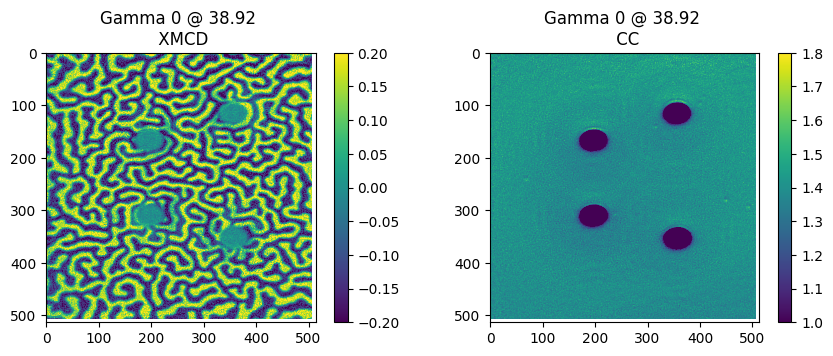

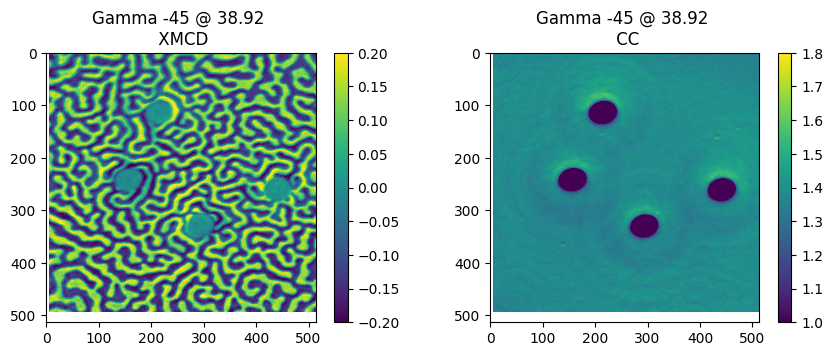

In [6]:
## Plot XMCD and CC of unscaled images
vmin = 1
vmax = 1.8
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
XMCD = axes[0].imshow(XMCD_0[k0], norm=norm)
axes[0].set_title(f"Gamma 0 @ {angle:.2f} \n XMCD") 
plt.colorbar(XMCD, ax = axes[0])
CC = axes[1].imshow(CC_0[k0], vmin = vmin, vmax = vmax)
axes[1].set_title(f"Gamma 0 @ {angle:.2f} \n CC") 
plt.colorbar(CC, ax = axes[1])
plt.show()

fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
XMCD = axes[0].imshow(XMCD_neg45[kneg45], norm=norm)
axes[0].set_title(f"Gamma -45 @ {angle:.2f} \n XMCD") 
plt.colorbar(XMCD, ax = axes[0])
CC = axes[1].imshow(CC_neg45[kneg45], vmin = vmin, vmax = vmax)
axes[1].set_title(f"Gamma -45 @ {angle:.2f} \n CC") 
plt.colorbar(CC, ax = axes[1])
plt.show()

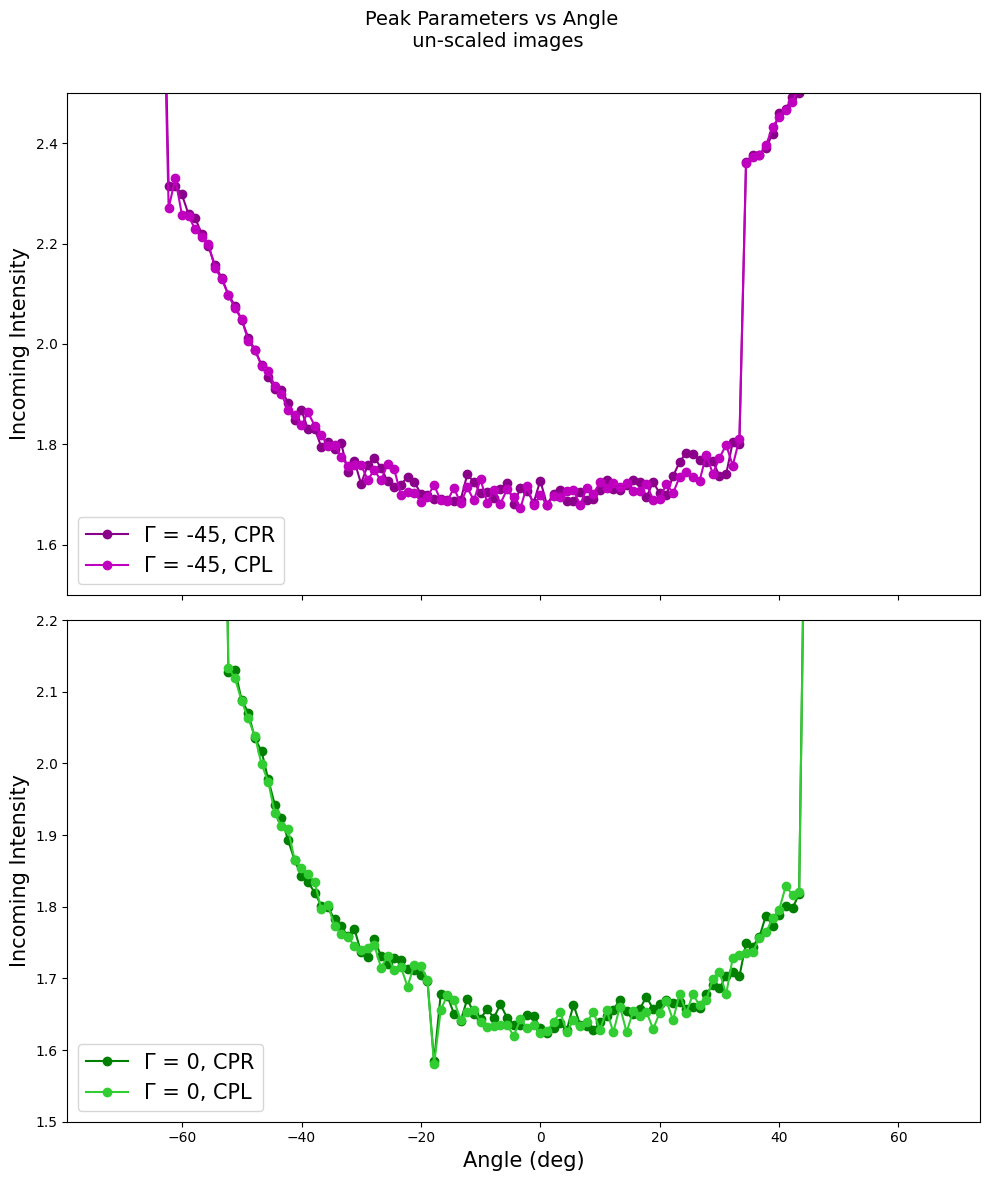

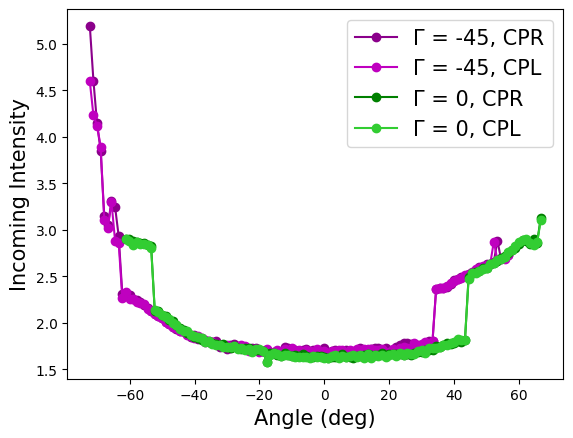

In [7]:
## track fiducial position over angle left and right

OG_fid_pos_neg45, OG_fid_neg_neg45 = [], []

for k in range(image_stack_pospol_neg45.shape[0]):

    ___, fid_avg_neg = auto_normalize_by_fiducial(image_stack_negpol_neg45[k], color_neg, plot_hist=False)
    ___, fid_avg_pos = auto_normalize_by_fiducial(image_stack_pospol_neg45[k], color_pos, plot_hist=False)
    
    OG_fid_pos_neg45.append(fid_avg_pos)
    OG_fid_neg_neg45.append(fid_avg_neg)

# Convert to numpy arrays
OG_fid_pos_neg45 = np.array(OG_fid_pos_neg45)
OG_fid_neg_neg45 = np.array(OG_fid_neg_neg45)


OG_fid_pos_0, OG_fid_neg_0 = [], []

for k in range(image_stack_pospol_0.shape[0]):

    ___, fid_avg_neg = auto_normalize_by_fiducial(image_stack_negpol_0[k], color_neg, plot_hist=False)
    ___, fid_avg_pos = auto_normalize_by_fiducial(image_stack_pospol_0[k], color_pos, plot_hist=False)
    
    OG_fid_pos_0.append(fid_avg_pos)
    OG_fid_neg_0.append(fid_avg_neg)

# Convert to numpy arrays
OG_fid_pos_0 = np.array(OG_fid_pos_0)
OG_fid_neg_0 = np.array(OG_fid_neg_0)


## plotting OG fid I
fig, axes = plt.subplots(2, 1, figsize=(10, 12), sharex=True)

axes[0].plot(angles_neg45, OG_fid_pos_neg45, 'o-', label="Γ = -45, CPR", color = 'darkmagenta' )
axes[0].plot(angles_neg45, OG_fid_neg_neg45, 'o-', label="Γ = -45, CPL", color = 'm')

axes[0].set_ylabel("Incoming Intensity", fontsize = '15')
axes[0].set_ylim(1.5, 2.5)
axes[0].legend(fontsize = '15')

axes[1].plot(angles_0, OG_fid_pos_0, 'o-', label="Γ = 0, CPR", color = 'green' )
axes[1].plot(angles_0, OG_fid_neg_0, 'o-', label="Γ = 0, CPL", color = 'limegreen')
axes[1].set_ylabel("Incoming Intensity", fontsize = '15')
axes[1].set_ylim(1.5, 2.2)
axes[1].legend(fontsize = '15')
axes[1].set_xlabel("Angle (deg)", fontsize = '15')

fig.suptitle(f"Peak Parameters vs Angle \n un-scaled images", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

plt.figure()
plt.plot(angles_neg45, OG_fid_pos_neg45, 'o-', label="Γ = -45, CPR", color = 'darkmagenta' )
plt.plot(angles_neg45, OG_fid_neg_neg45, 'o-', label="Γ = -45, CPL", color = 'm')
plt.plot(angles_0, OG_fid_pos_0, 'o-', label="Γ = 0, CPR", color = 'green' )
plt.plot(angles_0, OG_fid_neg_0, 'o-', label="Γ = 0, CPL", color = 'limegreen')
plt.legend(fontsize = '15')
plt.ylabel("Incoming Intensity", fontsize = '15')
plt.xlabel("Angle (deg)", fontsize = '15')
plt.show()



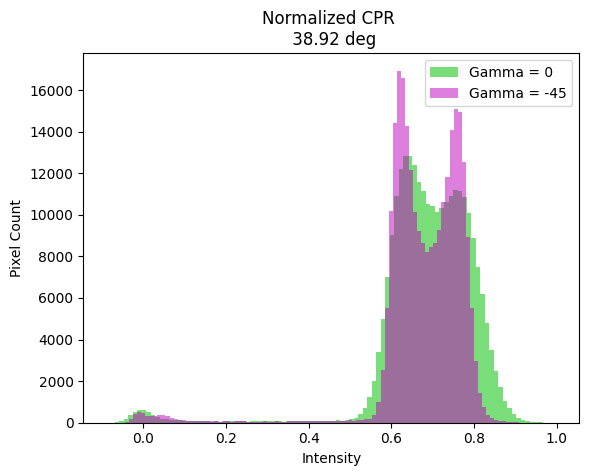

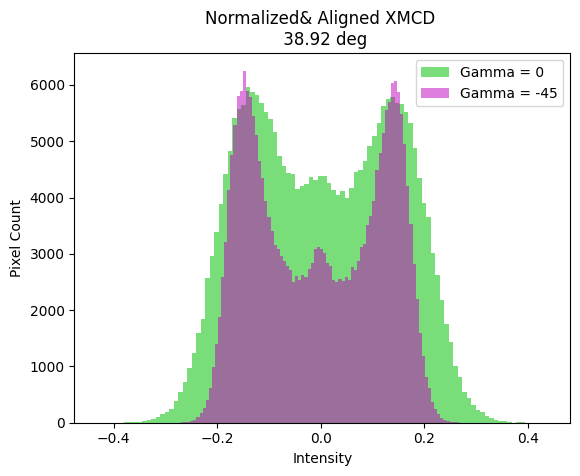

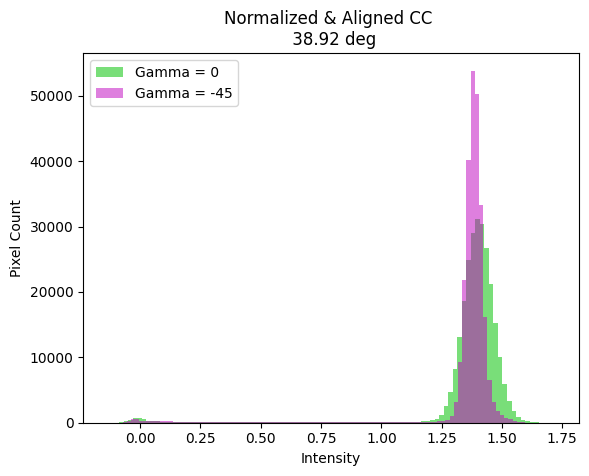

In [8]:
### Plot histograms and compare CPL,CC, and XMCD between Gamma
## Plot CPL
title = f'Normalized CPR \n {angle:.2f} deg'
vals_CC_neg45 = OD_img_pos_neg45.flatten()
# vals_CC_pos45 = OD_img_pos_pos45.flatten()
vals_CC_0 = OD_img_pos_0.flatten()

# plt.hist(vals_CC_pos45, bins = 100, alpha = 0.8, color = 'c', label = 'Gamma = +45')
plt.hist(vals_CC_0, bins = 100, alpha = 0.65, color = 'limegreen', label = 'Gamma = 0')
plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'm', label = 'Gamma = -45')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

## Plot XMCD
title = f'Normalized& Aligned XMCD \n {angle:.2f} deg'
vals_CC_neg45 = XMCD_neg45[kneg45].flatten()
# vals_CC_pos45 = XMCD_pos45.flatten()
vals_CC_0 = XMCD_0[k0].flatten()

# plt.hist(vals_CC_pos45, bins = 100, alpha = 0.8, color = 'c', label = 'Gamma = +45')
plt.hist(vals_CC_0, bins = 100, alpha = 0.65, color = 'limegreen', label = 'Gamma = 0')
plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'm', label = 'Gamma = -45')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

## Plot CC
title = f'Normalized & Aligned CC \n {angle:.2f} deg'
vals_CC_neg45 = CC_neg45[kneg45].flatten()
# vals_CC_pos45 = CC_pos45[k].flatten()
vals_CC_0 = CC_0[k0].flatten()

# plt.hist(vals_CC_pos45, bins = 100, alpha = 0.8, color = 'c', label = 'Gamma = +45')
plt.hist(vals_CC_0, bins = 100, alpha = 0.65, color = 'limegreen', label = 'Gamma = 0')
plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'm', label = 'Gamma = -45')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

In [9]:
# stop

# Scale charge peak to 1

20


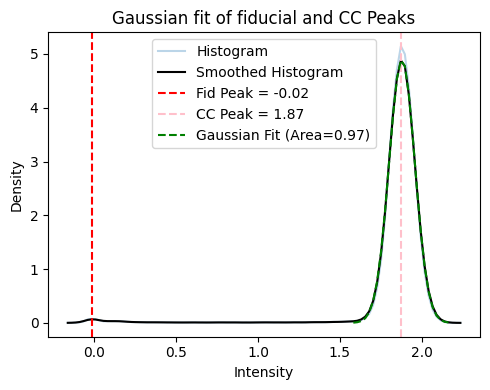

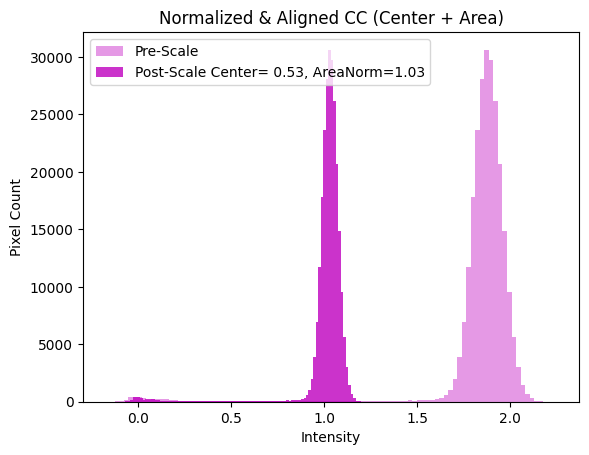

CC_peak_center_neg45 = 1.873037327155471
CC_FWHM_neg45 = 0.18653250541935587
area_gaussian = 0.9687974078351093


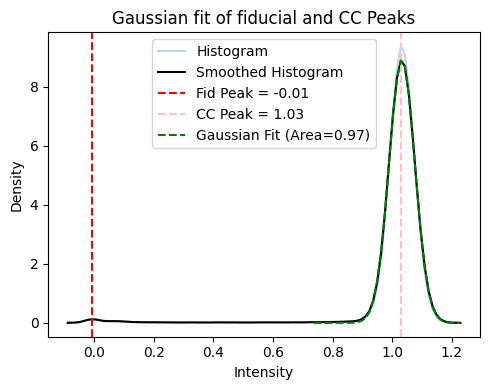

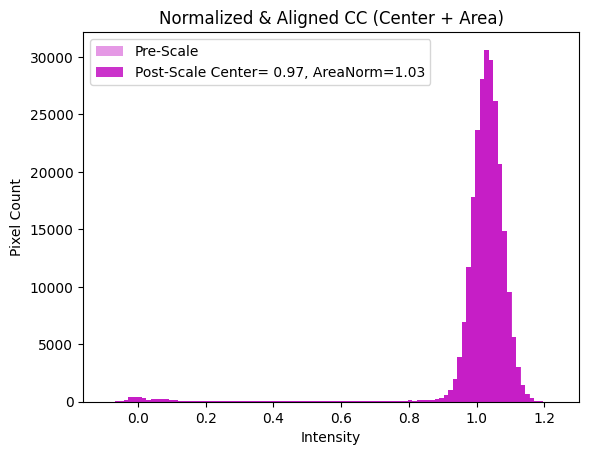

CC_peak_center_neg45 = 1.0287987990666647
CC_FWHM_neg45 = 0.10245626970700542
area_gaussian = 0.968803012376385


In [26]:
test = [20]
for k in test:  # scans = list of 2D images in your set
    print(k)
    # normalize_hist_neg45_test, CC_mean_neg45 , CC_peak_center_neg45, fid_peak_center_neg45, CC_FWHM_neg45, fid_FWHM_neg45   = auto_normalize_by_fiducial_log_FWHM_nan(CC_neg45[k], 'green', 'm')
    normalize_hist_neg45_test, CC_mean_neg45 , CC_peak_center_neg45, fid_peak_center_neg45, CC_FWHM_neg45, fid_FWHM_neg45, area_gaussian, area_norm_factor,(A_fit, mu_fit, sigma_fit) = normalize_CC1(CC_neg45[k], 'green', 'm')
    print(f'CC_peak_center_neg45 = {CC_peak_center_neg45}')
    print(f'CC_FWHM_neg45 = {CC_FWHM_neg45}')
    print(f'area_gaussian = {area_gaussian}')

    ____, CC_mean_neg45 , CC_peak_center_neg45, fid_peak_center_neg45, CC_FWHM_neg45, fid_FWHM_neg45, area_gaussian, area_norm_factor,(A_fit, mu_fit, sigma_fit) = normalize_CC1(normalize_hist_neg45_test, 'green', 'm')
    print(f'CC_peak_center_neg45 = {CC_peak_center_neg45}')
    print(f'CC_FWHM_neg45 = {CC_FWHM_neg45}')
    print(f'area_gaussian = {area_gaussian}')

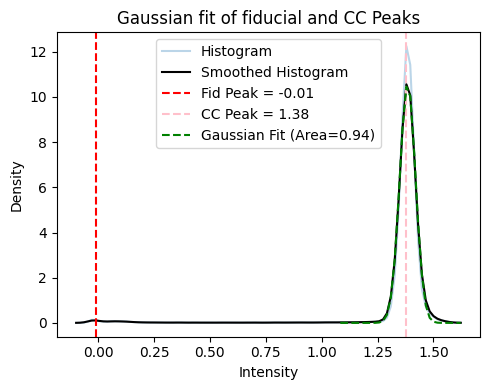

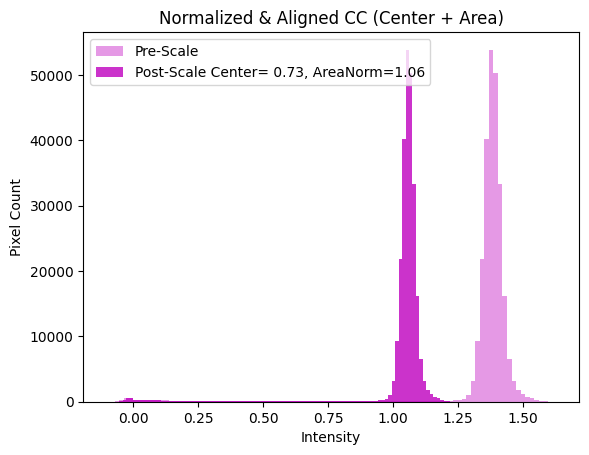

area_gaussian = 0.9430649672911922


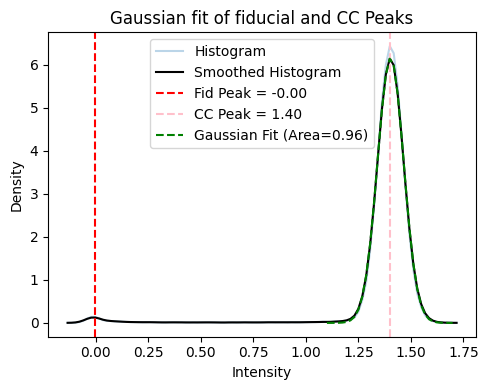

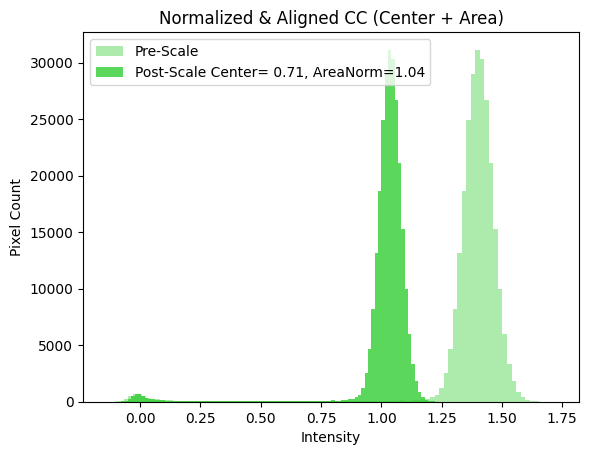

area_gaussian = 0.9647737299757163


In [11]:
## Perform scaling for alpha of interest here! control k0 and kneg45 above. 

normalize_hist_neg45, CC_mean_neg45 , CC_peak_center_neg45, fid_peak_center_neg45, CC_FWHM_neg45, fid_FWHM_neg45, area_gaussian, ___, ___  = normalize_CC1(CC_neg45[kneg45], 'green', 'm')
print(f'area_gaussian = {area_gaussian}')
normalize_hist_0, CC_mean_0, CC_peak_center_0, fid_peak_center_0, CC_FWHM_0, fid_FWHM_0, area_gaussian, ___, ___ = normalize_CC1(CC_0[k0], 'green', 'limegreen')
print(f'area_gaussian = {area_gaussian}')

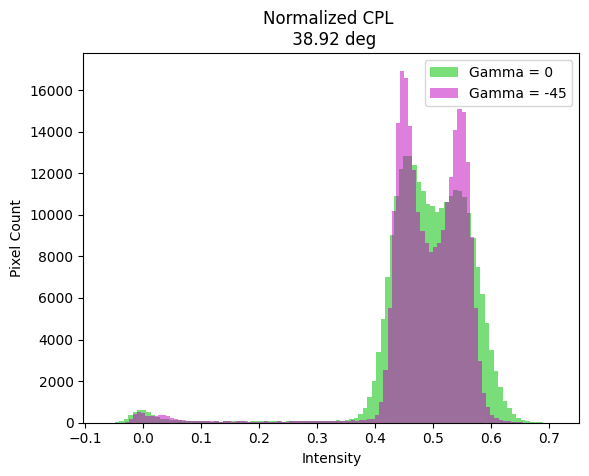

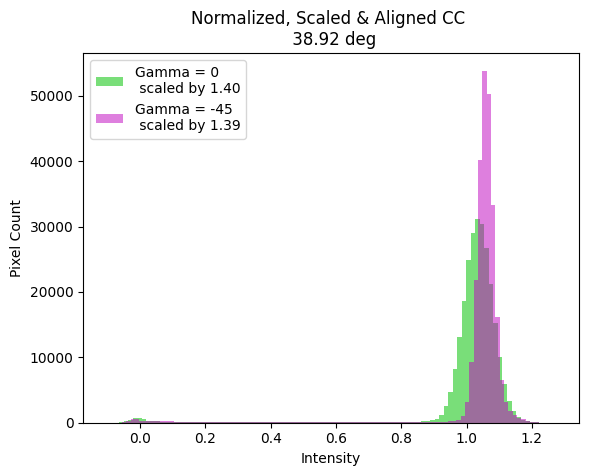

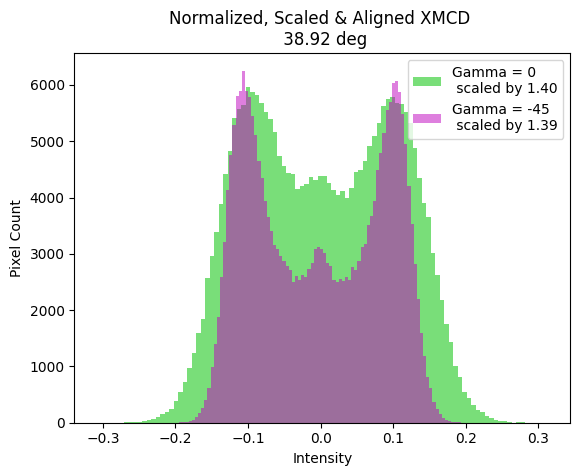

In [12]:
## plot histograms of CPL, CC, and XMCD of interest
## Plot CPL
title = f'Normalized CPL \n {angle:.2f} deg'
vals_CC_neg45 = OD_img_pos_neg45.flatten()/CC_mean_neg45
# vals_CC_pos45 = OD_img_pos_pos45.flatten()/CC_mean_pos45
vals_CC_0 = OD_img_pos_0.flatten()/CC_mean_0

# plt.hist(vals_CC_pos45, bins = 100, alpha = 0.8, color = 'c', label = 'Gamma = +45')
plt.hist(vals_CC_0, bins = 100, alpha = 0.65, color = 'limegreen', label = 'Gamma = 0')
plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'm', label = 'Gamma = -45')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()


## Plot CC
title = f'Normalized, Scaled & Aligned CC \n {angle:.2f} deg'
vals_CC_neg45 = normalize_hist_neg45.flatten()
# vals_CC_pos45 = normalize_hist_pos45.flatten()
vals_CC_0 = normalize_hist_0.flatten()

# plt.hist(vals_CC_pos45, bins = 100, alpha = 0.8, color = 'c', label = 'Gamma = +45')
plt.hist(vals_CC_0, bins = 100, alpha = 0.65, color = 'limegreen', label = f'Gamma = 0 \n scaled by {CC_mean_0:.2f}')
plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'm', label = f'Gamma = -45 \n scaled by {CC_mean_neg45:.2f}')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

## Scale XMCD 

scale_XMCD_0 = XMCD_0[k0]/CC_mean_0
scale_XMCD_neg45 = XMCD_neg45[kneg45]/CC_mean_neg45
# scale_XMCD_pos45 = norm_XMCD_pos45/CC_mean_pos45

## Plot
title = f'Normalized, Scaled & Aligned XMCD \n {angle:.2f} deg'
vals_CC_neg45 = scale_XMCD_neg45.flatten()
# vals_CC_pos45 = scale_XMCD_pos45.flatten()
vals_CC_0 = scale_XMCD_0.flatten()

# plt.hist(vals_CC_pos45, bins = 100, alpha = 0.8, color = 'c', label = f'Gamma = +45 \n scaled by {CC_mean_pos45:.2f}')
plt.hist(vals_CC_0, bins = 100, alpha = 0.65, color = 'limegreen', label = f'Gamma = 0 \n scaled by {CC_mean_0:.2f}')
plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'm', label = f'Gamma = -45 \n scaled by {CC_mean_neg45:.2f}')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

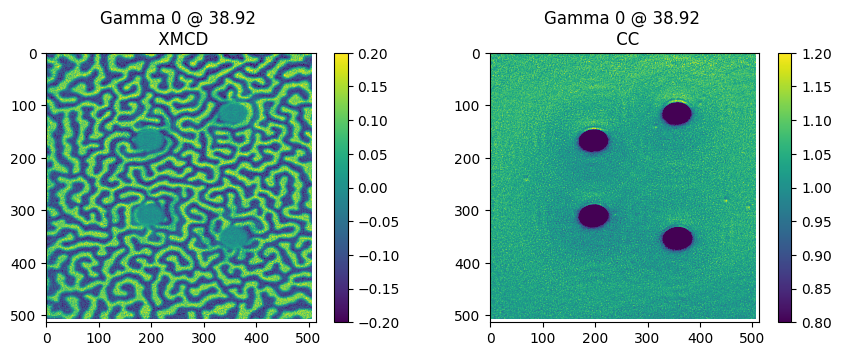

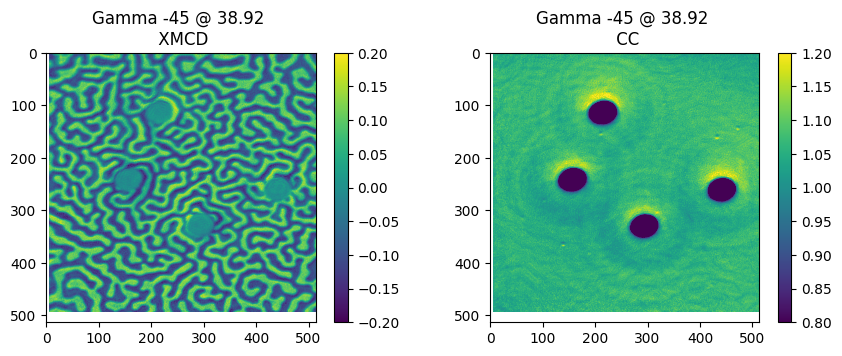

In [13]:
## Plot XMCD and CC for scaled images
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
XMCD = axes[0].imshow(scale_XMCD_0, norm=norm)
axes[0].set_title(f"Gamma 0 @ {angle:.2f} \n XMCD") 
plt.colorbar(XMCD, ax = axes[0])
CC = axes[1].imshow(normalize_hist_0, vmin = 0.8, vmax = 1.2)
axes[1].set_title(f"Gamma 0 @ {angle:.2f} \n CC") 
plt.colorbar(CC, ax = axes[1])
plt.show()

fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
XMCD = axes[0].imshow(scale_XMCD_neg45, norm=norm)
axes[0].set_title(f"Gamma -45 @ {angle:.2f} \n XMCD") 
plt.colorbar(XMCD, ax = axes[0])
CC = axes[1].imshow(normalize_hist_neg45, vmin = 0.8, vmax = 1.2)
axes[1].set_title(f"Gamma -45 @ {angle:.2f} \n CC") 
plt.colorbar(CC, ax = axes[1])
plt.show()

## Plot segments of this image with the intensity overlayed. 
- Asked ChatGPT: I have an image that I have made into a histogram. I want to select sections of the histogram and highlight where they are on the image in a seamless way (aka, select bin, pixels in that bin light up in the image). How can I do this in python? Thank you

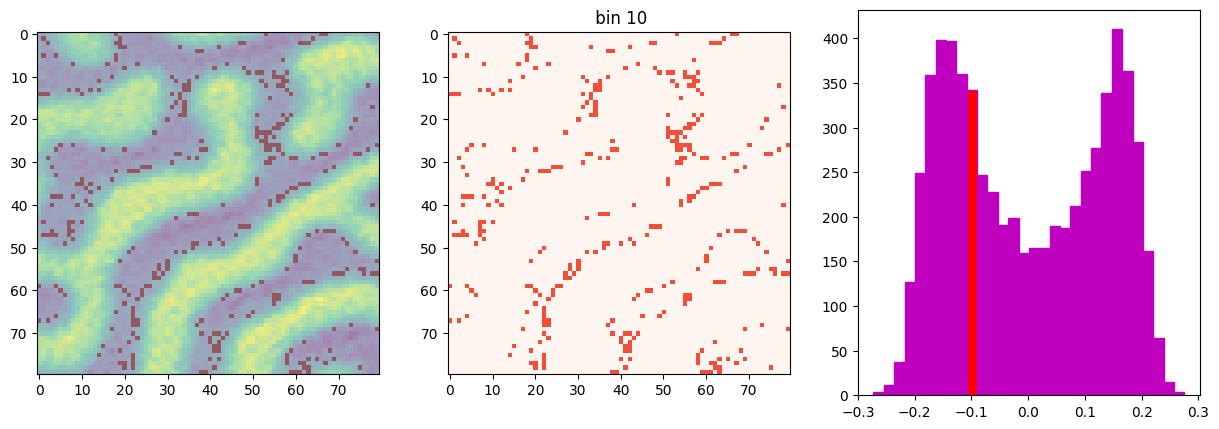

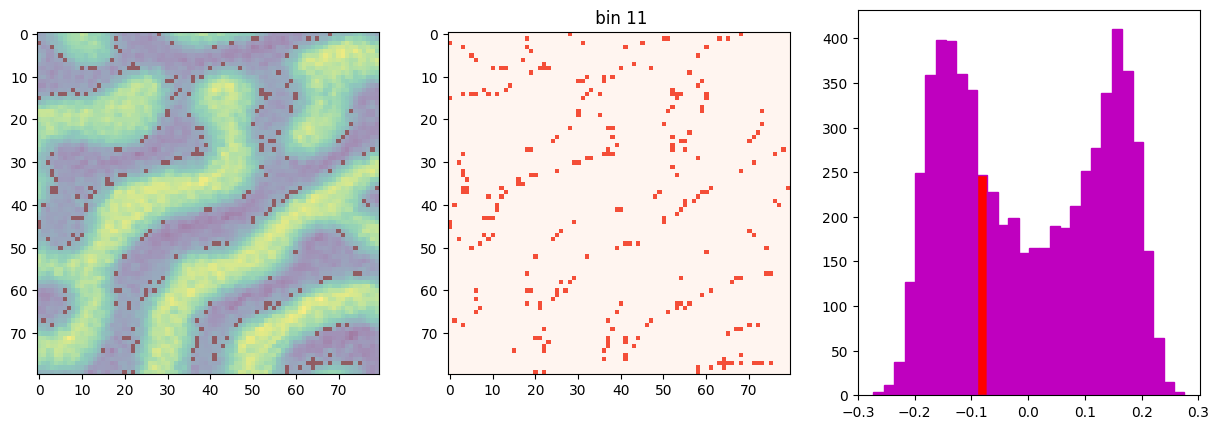

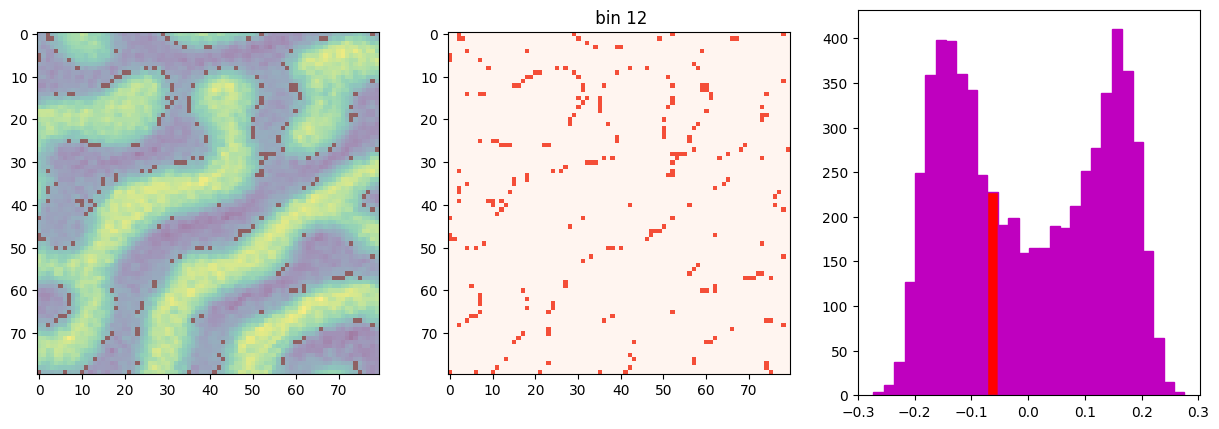

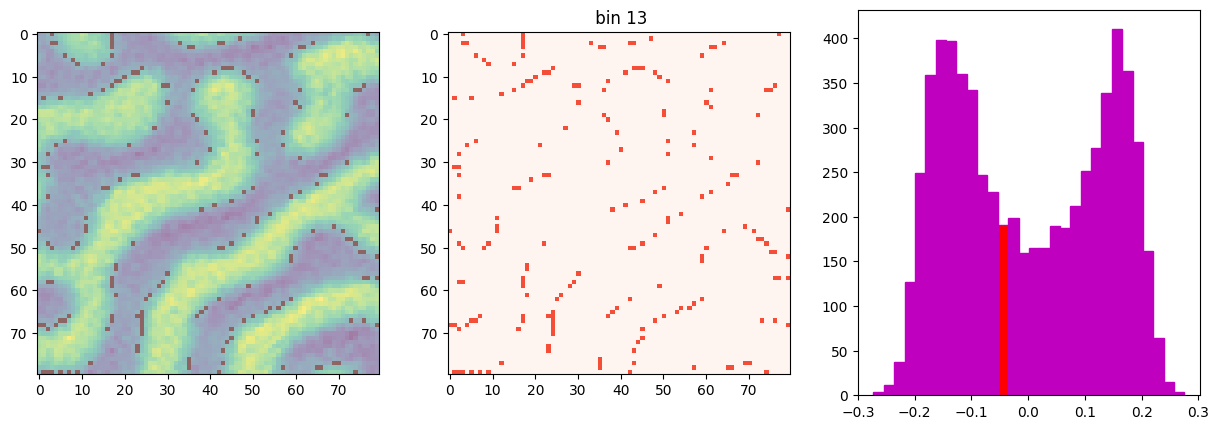

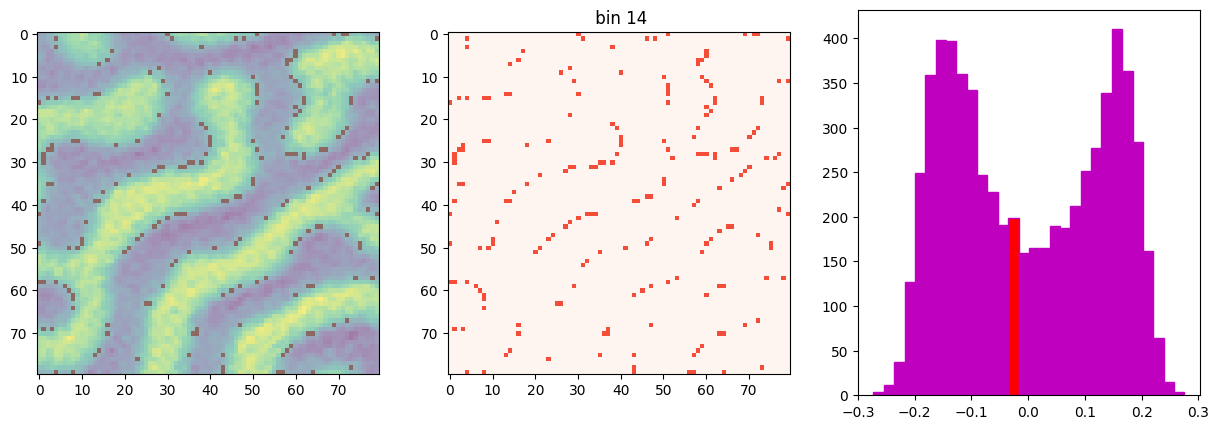

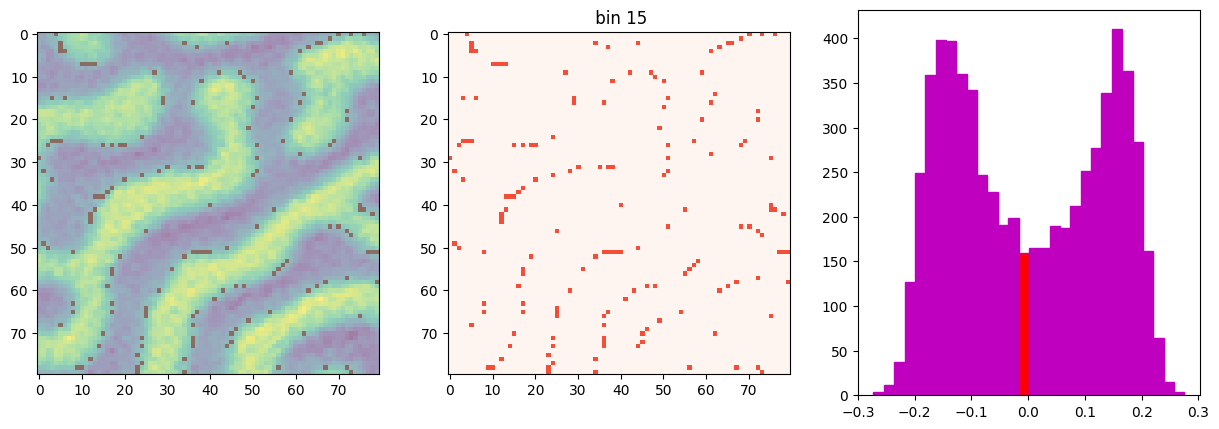

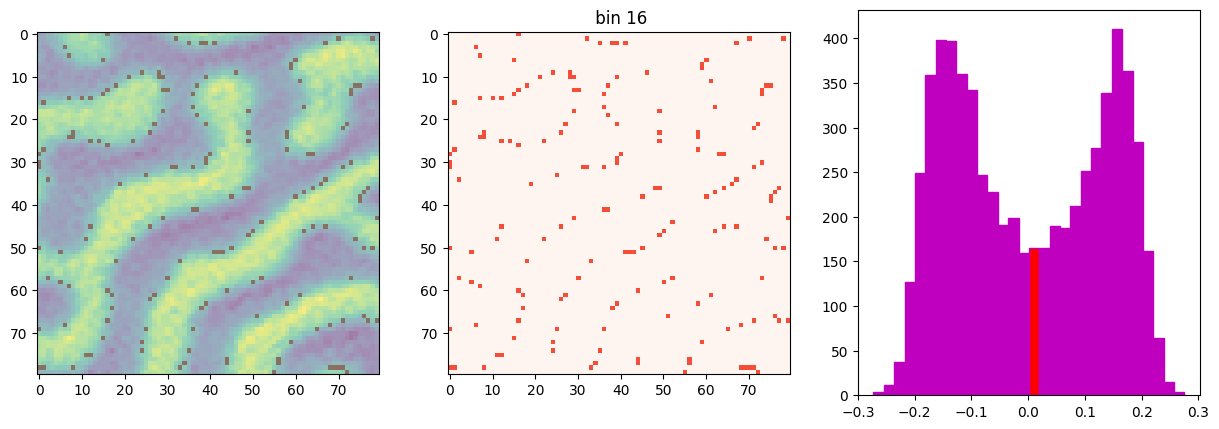

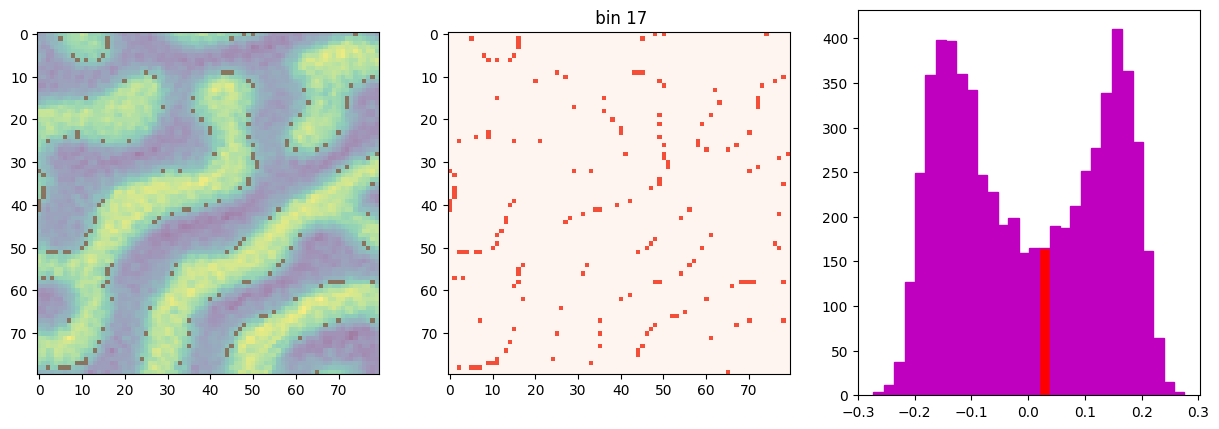

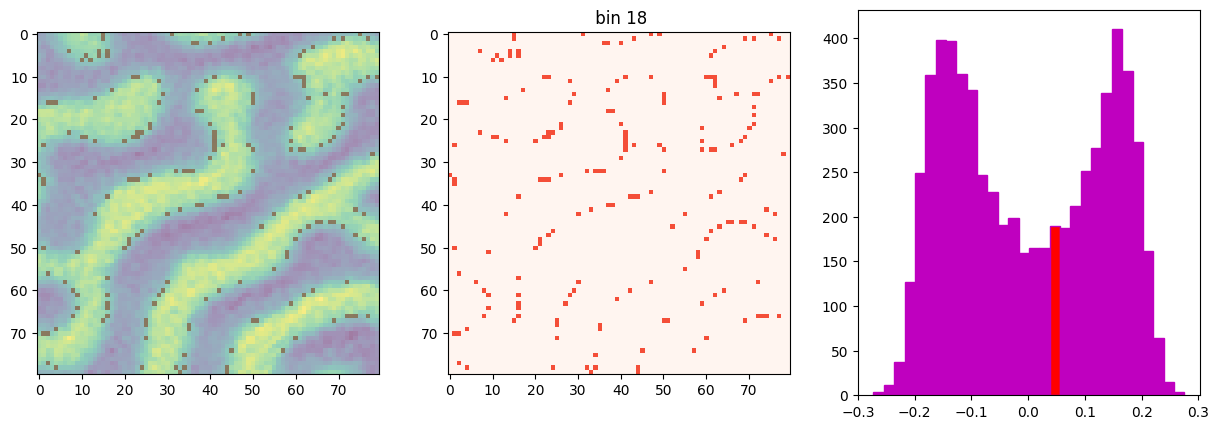

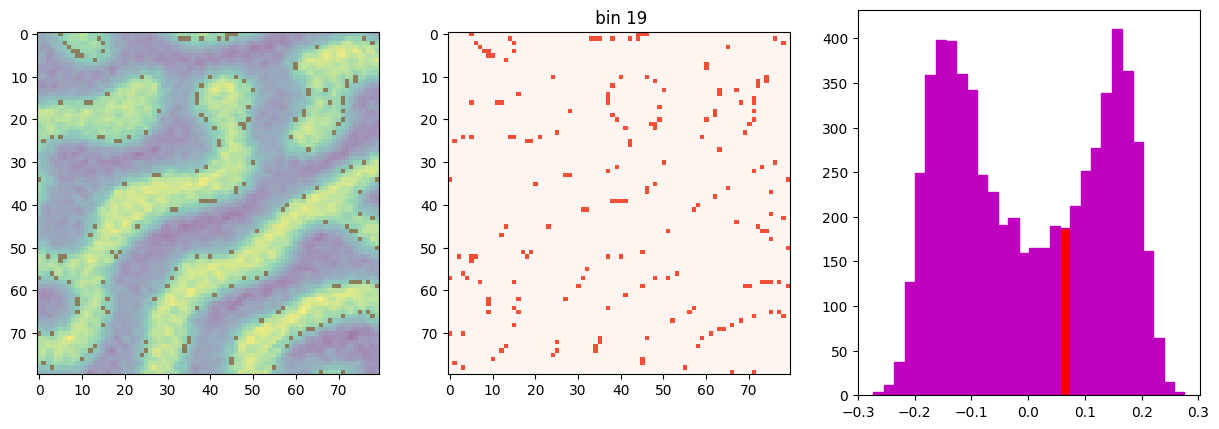

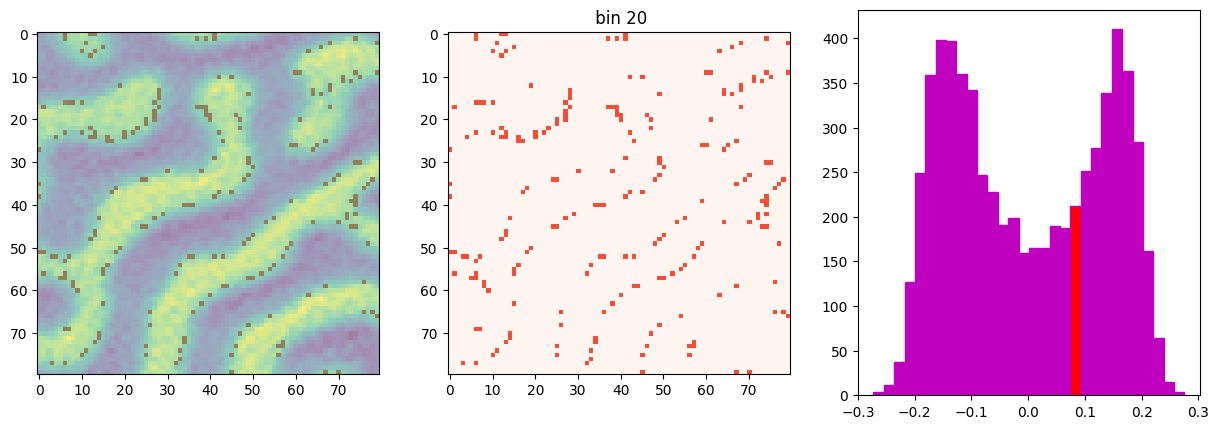

In [14]:
image_full = XMCD_neg45[kneg45]   
c = 'm'

# image_full = XMCD_0[k0]   
# c = 'limegreen'


half_size = 40 
height, width = image_full.shape

if c == 'limegreen':
    center_y = np.array([60, 300, 475, 60,  height // 2 - 40, 475, 60,  300, 475])
    center_x = np.array([60, 60, 60,   300, width // 2 + 10,  200, 475, 475, 475])
    i = 4

else:
    center_y = np.array([60, 300, 475, 60,  height // 2, 475, 60,  300, 475])
    center_x = np.array([60, 60, 60,   300, width // 2 ,  200, 475, 475, 475])

    # center_y = np.array([300])
    # center_x = np.array([250])
    
    i = 4
image = image_full[center_y[i] - half_size:center_y[i] + half_size,center_x[i] - half_size:center_x[i] + half_size]

def highlight_bin(bin_number):
    i = bin_number - 1
    if i < 0 or i >= len(bins) - 1:
        print("Bin number out of range")
        return
    low, high = bins[i], bins[i+1]
    mask = (image >= low) & (image < high)
    himg.set_data(mask.astype(float))
    maskedimg.set_data(mask.astype(float))

    # Reset histogram colors
    for p in patches:
        p.set_facecolor(c)
    patches[i].set_facecolor('red')

    fig.canvas.draw_idle()
    
# --- Iterate through bins with a pause ---
# show = [0,1,2,3,4,5,6,7,8,9,10]
show = [10,11,12,13,14,15,16,17,18,19,20]
# show = [20,21,22,23,24,25,26,27,28,29,30]

for i in show:
    # print(f"Showing bin {i}")

    # --- Setup figure ---
    fig, (ax_img, ax_mask, ax_hist) = plt.subplots(1, 3, figsize=(15, 5))
    
    # Show image
    ax_img.imshow(image, cmap='viridis')
    # ax_img.set_title(f"scale_XMCD_0, bin {i}")

    # Histogram (100 bins)
    counts, bins, patches = ax_hist.hist(
        image.ravel(), bins=30, color = c, edgecolor = c
    )
    # ax_hist.set_title("Histogram")
    
    # Overlay for highlighting (binary mask: 0 = no color, 1 = red)
    overlay = np.zeros_like(image, dtype=float)
    himg = ax_img.imshow(
        overlay, cmap='Reds', alpha=0.5,
        vmin=0, vmax=1.75, interpolation='nearest'
    )

    # Show image
    maskedimg = ax_mask.imshow(overlay, cmap='Reds', vmin = 0, vmax=1.75)
    ax_mask.set_title(f" bin {i}")
    
    highlight_bin(i)
    plt.show()
    plt.pause(0.5)   # pause 0.5s so the update is visible




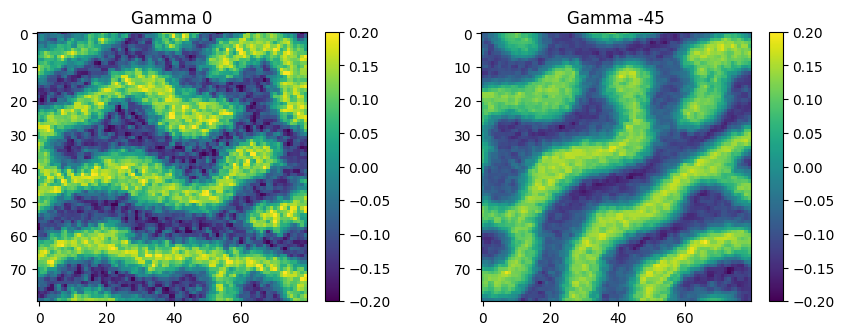

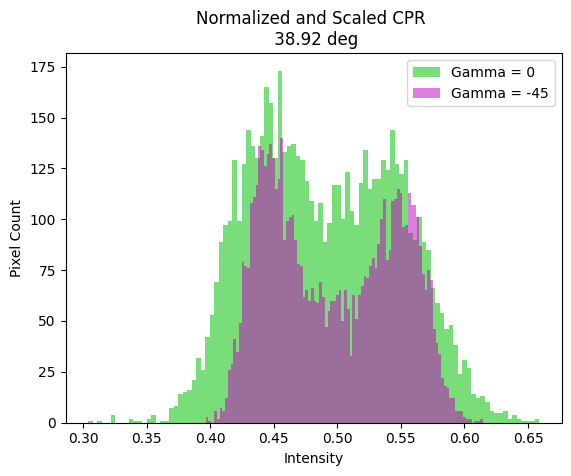

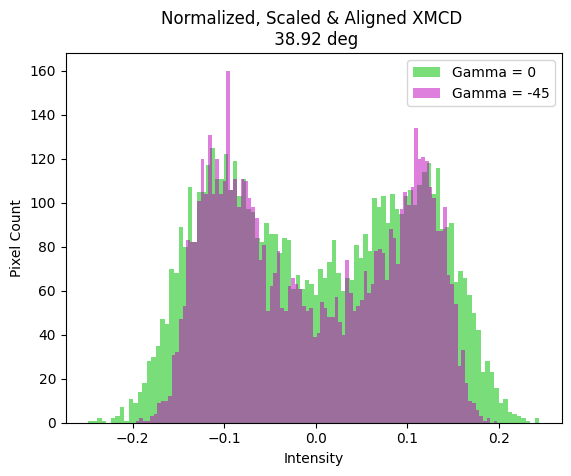

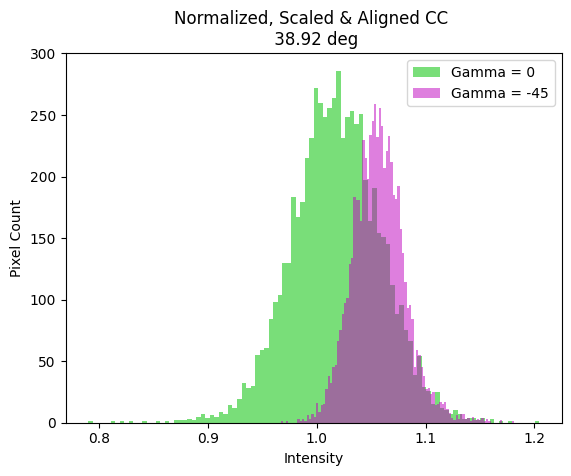

In [15]:
## Scaled histograms
half_size = 40 
height, width = image_full.shape
center_y = np.array([60, 300, 475, 60,  height // 2, 475, 60,  300, 475])
center_x = np.array([60, 60, 60,   300, width // 2,  200, 475, 475, 475])

center_y_0 = np.array([60, 300, 475, 60,  height // 2 - 30, 475, 60,  300, 475])
center_x_0 = np.array([60, 60, 60,   300, width // 2 -10 ,  200, 475, 475, 475])

i = 4
crop_XMCD_neg45 = scale_XMCD_neg45[center_y[i] - half_size:center_y[i] + half_size,
                          center_x[i] - half_size:center_x[i] + half_size]
# crop_XMCD_pos45 = norm_XMCD_pos45[center_y[i] - half_size:center_y[i] + half_size,
#                           center_x[i] - half_size:center_x[i] + half_size]
crop_XMCD_0 = scale_XMCD_0[center_y_0[i] - half_size:center_y_0[i] + half_size,
                          center_x_0[i] - half_size:center_x_0[i] + half_size]

crop_CPL_neg45 = (OD_img_pos_neg45/CC_mean_neg45)[center_y[i] - half_size:center_y[i] + half_size,
                          center_x[i] - half_size:center_x[i] + half_size]
# crop_CPL_pos45 = OD_img_pos_pos45[center_y[i] - half_size:center_y[i] + half_size,
#                           center_x[i] - half_size:center_x[i] + half_size]
crop_CPL_0 = (OD_img_pos_0/CC_mean_0)[center_y_0[i] - half_size:center_y_0[i] + half_size,
                          center_x_0[i] - half_size:center_x_0[i] + half_size]

crop_CC_neg45 = normalize_hist_neg45[center_y[i] - half_size:center_y[i] + half_size,
                          center_x[i] - half_size:center_x[i] + half_size]
# crop_CC_pos45 = norm_CC_pos45[center_y[i] - half_size:center_y[i] + half_size,
#                           center_x[i] - half_size:center_x[i] + half_size]
crop_CC_0 = normalize_hist_0[center_y_0[i] - half_size:center_y_0[i] + half_size,
                          center_x_0[i] - half_size:center_x_0[i] + half_size]



## Plot XMCD to see contrast a bit better, control norm above
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
XMCD = axes[0].imshow(crop_XMCD_0, norm=norm)
axes[0].set_title(f"Gamma 0") 
plt.colorbar(XMCD, ax = axes[0])
CC = axes[1].imshow(crop_XMCD_neg45, norm=norm)
axes[1].set_title(f"Gamma -45") 
plt.colorbar(CC, ax = axes[1])
plt.show()



## Plot CPL
title = f'Normalized and Scaled CPR \n {angle:.2f} deg'
vals_CC_neg45 = crop_CPL_neg45.flatten()
# vals_CC_pos45 = crop_CPL_pos45.flatten()
vals_CC_0 = crop_CPL_0.flatten()

# plt.hist(vals_CC_pos45, bins = 100, alpha = 0.8, color = 'c', label = 'Gamma = +45')
plt.hist(vals_CC_0, bins = 100, alpha = 0.65, color = 'limegreen', label = 'Gamma = 0')
plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'm', label = 'Gamma = -45')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

## Plot XMCD
title = f'Normalized, Scaled & Aligned XMCD \n {angle:.2f} deg'
vals_CC_neg45 = crop_XMCD_neg45.flatten()
# vals_CC_pos45 = crop_XMCD_pos45.flatten()
vals_CC_0 = crop_XMCD_0.flatten()

# plt.hist(vals_CC_pos45, bins = 100, alpha = 0.8, color = 'c', label = 'Gamma = +45')
plt.hist(vals_CC_0, bins = 100, alpha = 0.65, color = 'limegreen', label = 'Gamma = 0')
plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'm', label = 'Gamma = -45')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

## Plot CC
title = f'Normalized, Scaled & Aligned CC \n {angle:.2f} deg'
vals_CC_neg45 = crop_CC_neg45.flatten()
# vals_CC_pos45 = crop_CC_pos45.flatten()
vals_CC_0 = crop_CC_0.flatten()

# plt.hist(vals_CC_pos45, bins = 100, alpha = 0.8, color = 'c', label = 'Gamma = +45')
plt.hist(vals_CC_0, bins = 100, alpha = 0.65, color = 'limegreen', label = 'Gamma = 0')
plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'm', label = 'Gamma = -45')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

100
90


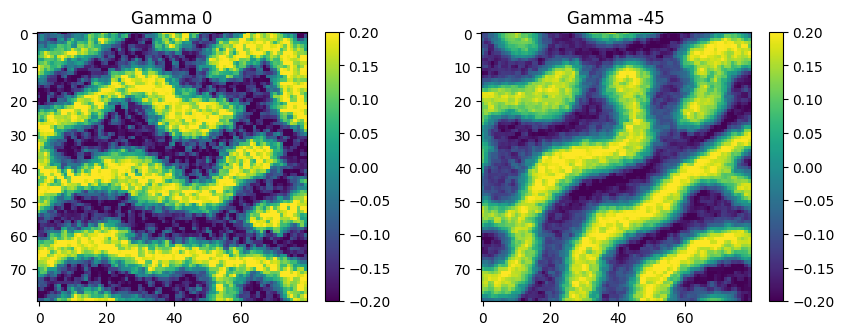

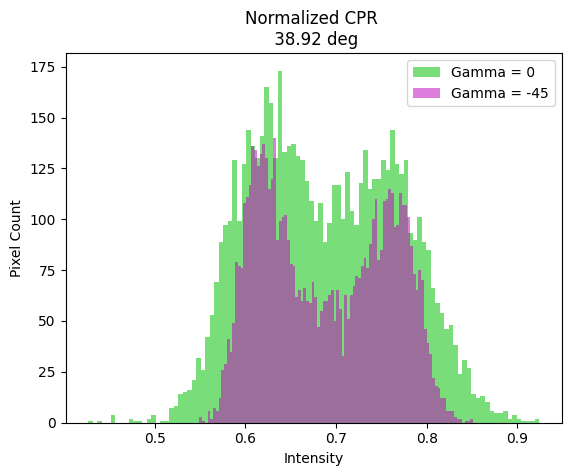

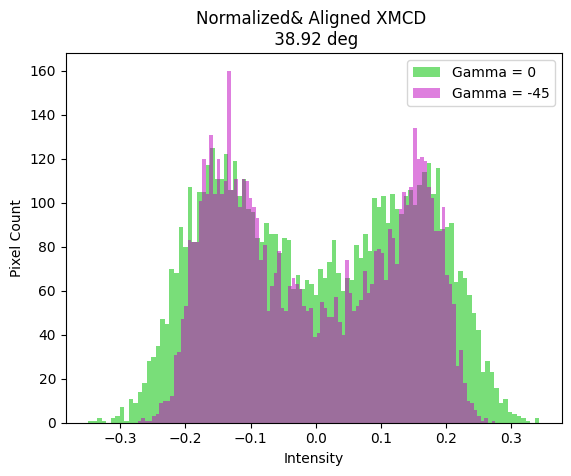

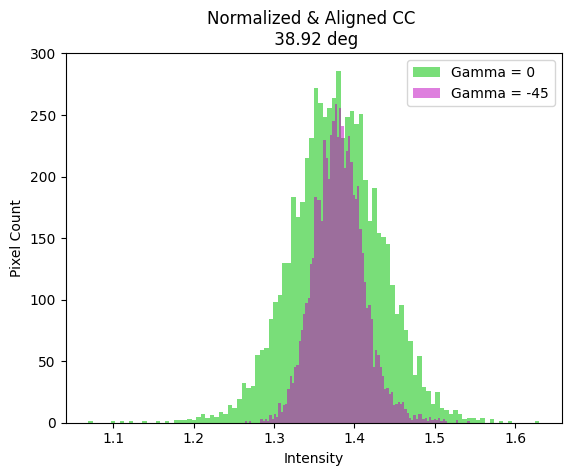

In [16]:
## unscaled histograms 
print(kneg45)
print(k0)
half_size = 40 
height, width = image_full.shape
center_y = np.array([60, 300, 475, 60, height // 2, 475, 60,  300, 475])
center_x = np.array([60, 60, 60,   300, width // 2,  200, 475, 475, 475])
center_y_0 = np.array([60, 300, 475, 60,  height // 2 - 30, 475, 60,  300, 475])
center_x_0 = np.array([60, 60, 60,   300, width // 2 -10 ,  200, 475, 475, 475])

i = 4
crop_XMCD_neg45 = XMCD_neg45[kneg45][center_y[i] - half_size:center_y[i] + half_size,
                          center_x[i] - half_size:center_x[i] + half_size]
# crop_XMCD_pos45 = norm_XMCD_pos45[center_y[i] - half_size:center_y[i] + half_size,
#                           center_x[i] - half_size:center_x[i] + half_size]
crop_XMCD_0 = XMCD_0[k0][center_y_0[i] - half_size:center_y_0[i] + half_size,
                          center_x_0[i] - half_size:center_x_0[i] + half_size]

crop_CPL_neg45 = OD_img_pos_neg45[center_y[i] - half_size:center_y[i] + half_size,
                          center_x[i] - half_size:center_x[i] + half_size]
# crop_CPL_pos45 = OD_img_pos_pos45[center_y[i] - half_size:center_y[i] + half_size,
#                           center_x[i] - half_size:center_x[i] + half_size]
crop_CPL_0 = OD_img_pos_0[center_y_0[i] - half_size:center_y_0[i] + half_size,
                          center_x_0[i] - half_size:center_x_0[i] + half_size]

crop_CC_neg45 = CC_neg45[kneg45][center_y[i] - half_size:center_y[i] + half_size,
                          center_x[i] - half_size:center_x[i] + half_size]
# crop_CC_pos45 = norm_CC_pos45[center_y[i] - half_size:center_y[i] + half_size,
#                           center_x[i] - half_size:center_x[i] + half_size]
crop_CC_0 = CC_0[k0][center_y_0[i] - half_size:center_y_0[i] + half_size,
                          center_x_0[i] - half_size:center_x_0[i] + half_size]


## Plot XMCD to see contrast a bit better, control norm above
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
XMCD = axes[0].imshow(crop_XMCD_0, norm=norm)
axes[0].set_title(f"Gamma 0") 
plt.colorbar(XMCD, ax = axes[0])
CC = axes[1].imshow(crop_XMCD_neg45, norm=norm)
axes[1].set_title(f"Gamma -45") 
plt.colorbar(CC, ax = axes[1])
plt.show()


## Plot CPL
title = f'Normalized CPR \n {angle:.2f} deg'
vals_CC_neg45 = crop_CPL_neg45.flatten()
# vals_CC_pos45 = crop_CPL_pos45.flatten()
vals_CC_0 = crop_CPL_0.flatten()

# plt.hist(vals_CC_pos45, bins = 100, alpha = 0.8, color = 'c', label = 'Gamma = +45')
plt.hist(vals_CC_0, bins = 100, alpha = 0.65, color = 'limegreen', label = 'Gamma = 0')
plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'm', label = 'Gamma = -45')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

## Plot XMCD
title = f'Normalized& Aligned XMCD \n {angle:.2f} deg'
vals_CC_neg45 = crop_XMCD_neg45.flatten()
# vals_CC_pos45 = crop_XMCD_pos45.flatten()
vals_CC_0 = crop_XMCD_0.flatten()

# plt.hist(vals_CC_pos45, bins = 100, alpha = 0.8, color = 'c', label = 'Gamma = +45')
plt.hist(vals_CC_0, bins = 100, alpha = 0.65, color = 'limegreen', label = 'Gamma = 0')
plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'm', label = 'Gamma = -45')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

## Plot CC
title = f'Normalized & Aligned CC \n {angle:.2f} deg'
vals_CC_neg45 = crop_CC_neg45.flatten()
# vals_CC_pos45 = crop_CC_pos45.flatten()
vals_CC_0 = crop_CC_0.flatten()

# plt.hist(vals_CC_pos45, bins = 100, alpha = 0.8, color = 'c', label = 'Gamma = +45')
plt.hist(vals_CC_0, bins = 100, alpha = 0.65, color = 'limegreen', label = 'Gamma = 0')
plt.hist(vals_CC_neg45, bins = 100, alpha = 0.5, color = 'm', label = 'Gamma = -45')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

# Iterate over all scaling and plot FWHM and peak position 

In [17]:
## For loop around unscaled, saving the ratios and the scaled images 
scale_CC_neg45_all = np.zeros_like(CC_neg45)
scale_CC_0_all = np.zeros_like(CC_0)


CC_means_neg45_unscale, CC_centers_neg45_unscale, CC_FWHMs_neg45_unscale = [], [], []
fid_centers_neg45_unscale, fid_FWHMs_neg45_unscale = [], []
CC_area_neg45_unscale = []

for k in range(image_stack_pospol_neg45.shape[0]):
    # normalized_image, CC_mean , CC_center, fid_center, CC_FWHM, fid_FWHM  = auto_normalize_by_fiducial_log_FWHM_nan(CC_neg45[k], 'green', 'm', plot_hist=False)
    # normalized_image, CC_mean, CC_center, fid_center, CC_FWHM, fid_FWHM, area_gaussian, (A_fit, mu_fit, sigma_fit) = auto_normalize_by_fiducial_log_FWHM_nan_area(CC_neg45[k], 'green', 'm', plot_hist=False)
    normalized_image, CC_mean, CC_center, fid_center, CC_FWHM, fid_FWHM, area_gaussian, area_norm_factor, (A_fit, mu_fit, sigma_fit) = normalize_CC1(CC_neg45[k], 'green', 'm', plot_hist=False)


    CC_means_neg45_unscale.append(CC_mean)
    CC_centers_neg45_unscale.append(CC_center)
    CC_FWHMs_neg45_unscale.append(CC_FWHM)
    fid_centers_neg45_unscale.append(fid_center)
    fid_FWHMs_neg45_unscale.append(fid_FWHM)
    CC_area_neg45_unscale.append(area_gaussian)

    scale_CC_neg45_all[k] = normalized_image

# Convert to numpy arrays
CC_means_neg45_unscale = np.array(CC_means_neg45_unscale)
CC_centers_neg45_unscale = np.array(CC_centers_neg45_unscale)
CC_FWHMs_neg45_unscale = np.array(CC_FWHMs_neg45_unscale)
fid_centers_neg45_unscale = np.array(fid_centers_neg45_unscale)
fid_FWHMs_neg45_unscale = np.array(fid_FWHMs_neg45_unscale)
CC_area_neg45_unscale = np.array(CC_area_neg45_unscale)


CC_means_0_unscale, CC_centers_0_unscale, CC_FWHMs_0_unscale = [], [], []
fid_centers_0_unscale, fid_FWHMs_0_unscale = [], []
CC_area_0_unscale = []

for k in range(image_stack_pospol_0.shape[0]):
    #normalized_image, CC_mean , CC_center, fid_center, CC_FWHM, fid_FWHM   = auto_normalize_by_fiducial_log_FWHM_nan(CC_0[k], 'green', 'limegreen', plot_hist=False)
    #normalized_image, CC_mean, CC_center, fid_center, CC_FWHM, fid_FWHM, area_gaussian, (A_fit, mu_fit, sigma_fit) = auto_normalize_by_fiducial_log_FWHM_nan_area(CC_0[k], 'green', 'm', plot_hist=False)
    normalized_image, CC_mean, CC_center, fid_center, CC_FWHM, fid_FWHM, area_gaussian, area_norm_factor, (A_fit, mu_fit, sigma_fit) = normalize_CC1(CC_0[k], 'green', 'm', plot_hist=False)
    
    CC_means_0_unscale.append(CC_mean)
    CC_centers_0_unscale.append(CC_center)
    CC_FWHMs_0_unscale.append(CC_FWHM)
    fid_centers_0_unscale.append(fid_center)
    fid_FWHMs_0_unscale.append(fid_FWHM)
    CC_area_0_unscale.append(area_gaussian)

    scale_CC_0_all[k] = normalized_image

# Convert to numpy arrays
CC_means_0_unscale = np.array(CC_means_0_unscale)
CC_centers_0_unscale = np.array(CC_centers_0_unscale)
CC_FWHMs_0_unscale = np.array(CC_FWHMs_0_unscale)
fid_centers_0_unscale = np.array(fid_centers_0_unscale)
fid_FWHMs_0_unscale = np.array(fid_FWHMs_0_unscale)
CC_area_0_unscale = np.array(CC_area_0_unscale)

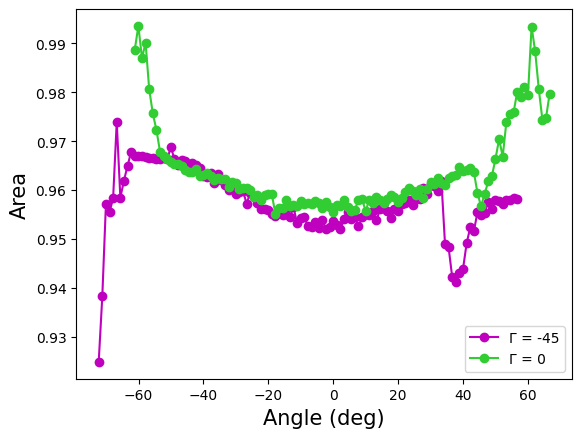

In [18]:
plt.plot( angles_neg45,CC_area_neg45_unscale,  'o-', label="Γ = -45", color = 'm')
plt.plot( angles_0,CC_area_0_unscale, 'o-', label="Γ = 0", color = 'limegreen' )
plt.ylabel('Area', fontsize = '15')
plt.xlabel('Angle (deg)', fontsize = '15')
plt.legend()
plt.show()

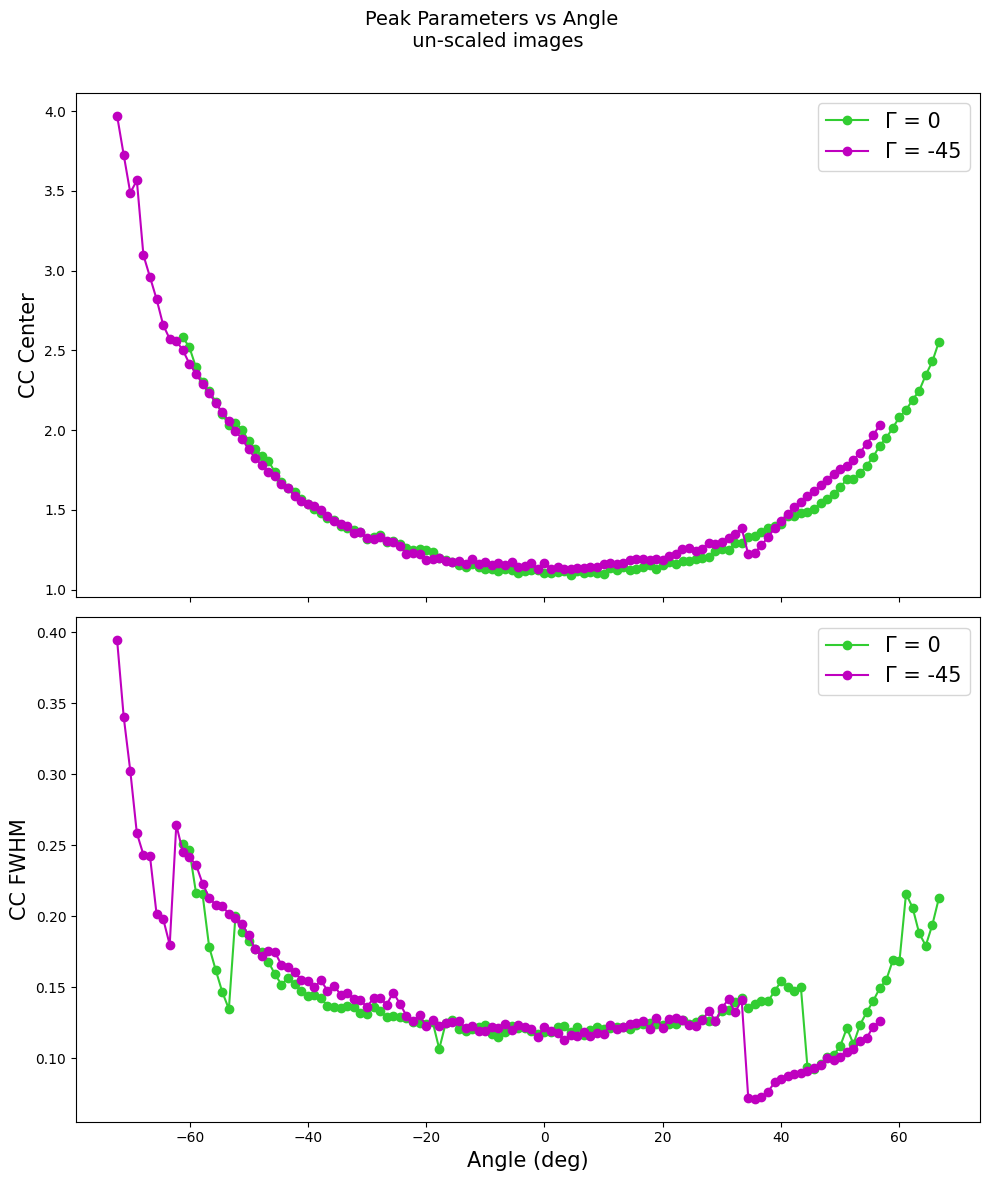

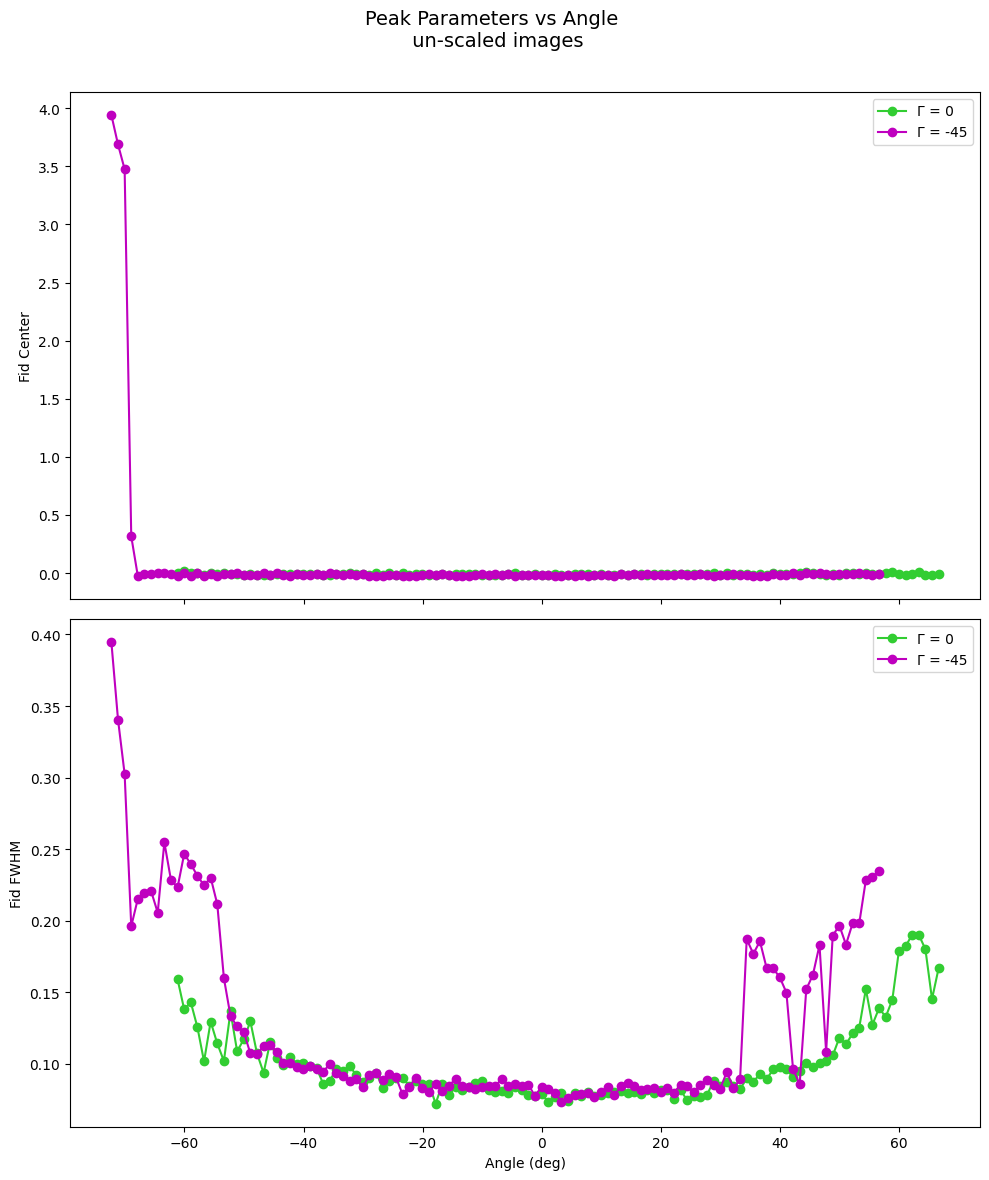

In [19]:
## plotting FWHM and Centers for the unscaled images
fig, axes = plt.subplots(2, 1, figsize=(10, 12), sharex=True)

axes[0].plot(angles_0, CC_centers_0_unscale, 'o-', label="Γ = 0", color = 'limegreen' )
axes[0].plot(angles_neg45, CC_means_neg45_unscale, 'o-', label="Γ = -45", color = 'm')
# axes[0].plot(angles_pos45, CC_centers_pos45, 'o-', label="Γ = +45", color = 'c')
axes[0].set_ylabel("CC Center", fontsize = '15')
# axes[0].set_ylim(1, 1.5)
axes[0].legend(fontsize = '15')

axes[1].plot(angles_0, CC_FWHMs_0_unscale, 'o-', label="Γ = 0", color = 'limegreen' )
axes[1].plot(angles_neg45, CC_FWHMs_neg45_unscale, 'o-', label="Γ = -45", color = 'm')
# axes[1].plot(angles_pos45, CC_FWHMs_pos45, 'o-', label="Γ = +45", color = 'orange')
axes[1].set_ylabel("CC FWHM", fontsize = '15')
# axes[1].set_ylim(0.1, 0.2)
axes[1].legend(fontsize = '15')
axes[1].set_xlabel("Angle (deg)", fontsize = '15')

fig.suptitle(f"Peak Parameters vs Angle \n un-scaled images", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


fig, axes = plt.subplots(2, 1, figsize=(10, 12), sharex=True)
axes[0].plot(angles_0, fid_centers_0_unscale, 'o-', label="Γ = 0", color = 'limegreen' )
axes[0].plot(angles_neg45, fid_centers_neg45_unscale, 'o-', label="Γ = -45", color = 'm')
# axes[2].plot(angles_pos45, fid_centers_pos45, 'o-', label="Γ = +45", color = 'limegreen')
axes[0].set_ylabel("Fid Center")
axes[0].legend()

axes[1].plot(angles_0, fid_FWHMs_0_unscale, 'o-', label="Γ = 0", color = 'limegreen' )
axes[1].plot(angles_neg45, fid_FWHMs_neg45_unscale, 'o-', label="Γ = -45", color = 'm')
# axes[3].plot(angles_pos45, fid_FWHMs_pos45, 'o-', label="Γ = +45", color = 'm')
axes[1].set_ylabel("Fid FWHM")
axes[1].set_xlabel("Angle (deg)")
axes[1].legend()

fig.suptitle(f"Peak Parameters vs Angle \n un-scaled images", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


In [20]:
## For loop around scaled, saving the ratios and the scaled images 
CC_means_neg45_scale, CC_centers_neg45_scale, CC_FWHMs_neg45_scale = [], [], []
fid_centers_neg45_scale, fid_FWHMs_neg45_scale = [], []
CC_area_neg45_scale = []

CC_means_0_scale, CC_centers_0_scale, CC_FWHMs_0_scale= [], [], []
fid_centers_0_scale, fid_FWHMs_0_scale = [], []
CC_area_0_scale = []


for k in range(CC_neg45.shape[0]):  # scans = list of 2D images in your set
    #__, CC_mean , CC_center, fid_center, CC_FWHM, fid_FWHM  = auto_normalize_by_fiducial_log_FWHM_nan(scale_CC_neg45_all[k], 'green', 'm', plot_hist=False)
    __, CC_mean, CC_center, fid_center, CC_FWHM, fid_FWHM, area_gaussian, area_norm_factor, (A_fit, mu_fit, sigma_fit) = normalize_CC1(scale_CC_neg45_all[k], 'green', 'm', plot_hist=False)

    CC_means_neg45_scale.append(CC_mean)
    CC_centers_neg45_scale.append(CC_center)
    CC_FWHMs_neg45_scale.append(CC_FWHM)
    fid_centers_neg45_scale.append(fid_center)
    fid_FWHMs_neg45_scale.append(fid_FWHM)
    CC_area_neg45_scale.append(area_gaussian)

# Convert to numpy arrays
CC_means_neg45_scale = np.array(CC_means_neg45_scale)
CC_centers_neg45_scale = np.array(CC_centers_neg45_scale)
CC_FWHMs_neg45_scale = np.array(CC_FWHMs_neg45_scale)
fid_centers_neg45_scale = np.array(fid_centers_neg45_scale)
fid_FWHMs_neg45_scale = np.array(fid_FWHMs_neg45_scale)
CC_area_neg45_scale = np.array(CC_area_neg45_scale)

for k in range(CC_0.shape[0]):  # scans = list of 2D images in your set
    #__, CC_mean , CC_center, fid_center, CC_FWHM, fid_FWHM  = auto_normalize_by_fiducial_log_FWHM_nan(scale_CC_0_all[k], 'green', 'm', plot_hist=False)
    __, CC_mean, CC_center, fid_center, CC_FWHM, fid_FWHM, area_gaussian, area_norm_factor, (A_fit, mu_fit, sigma_fit) = normalize_CC1(scale_CC_0_all[k], 'green', 'm', plot_hist=False)

    CC_means_0_scale.append(CC_mean)
    CC_centers_0_scale.append(CC_center)
    CC_FWHMs_0_scale.append(CC_FWHM)
    fid_centers_0_scale.append(fid_center)
    fid_FWHMs_0_scale.append(fid_FWHM)
    CC_area_0_scale.append(area_gaussian)

# Convert to numpy arrays
CC_means_0_scale = np.array(CC_means_0_scale)
CC_centers_0_scale = np.array(CC_centers_0_scale)
CC_FWHMs_0_scale = np.array(CC_FWHMs_0_scale)
fid_centers_0_scale = np.array(fid_centers_0_scale)
fid_FWHMs_0_scale = np.array(fid_FWHMs_0_scale)
CC_area_0_scale = np.array(CC_area_0_scale)

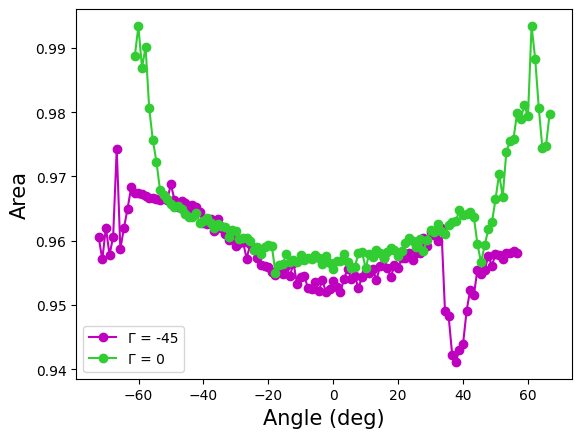

In [21]:
plt.plot( angles_neg45,CC_area_neg45_scale,  'o-', label="Γ = -45", color = 'm')
plt.plot( angles_0,CC_area_0_scale, 'o-', label="Γ = 0", color = 'limegreen' )
plt.ylabel('Area', fontsize = '15')
plt.xlabel('Angle (deg)', fontsize = '15')
plt.legend()
plt.show()

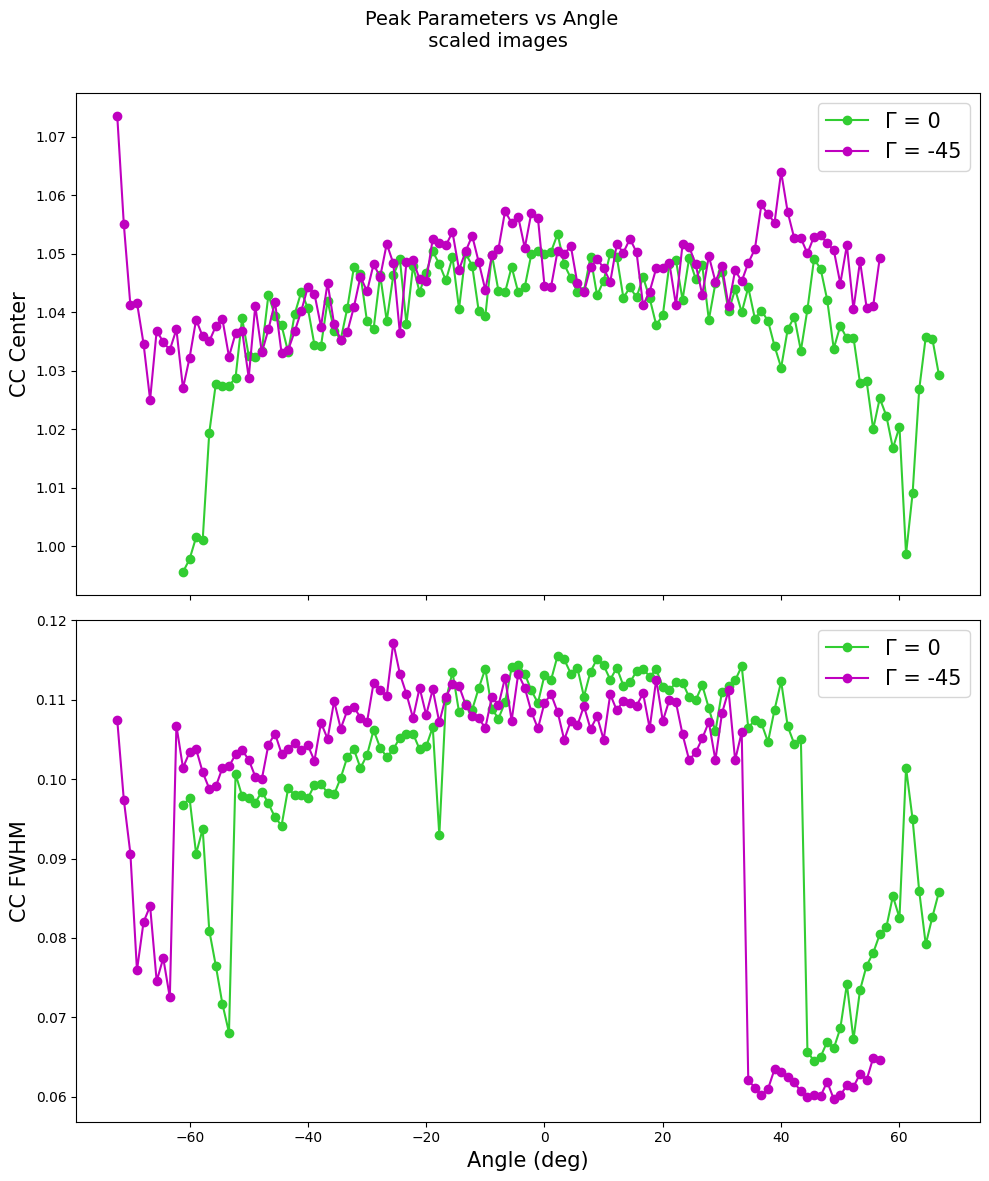

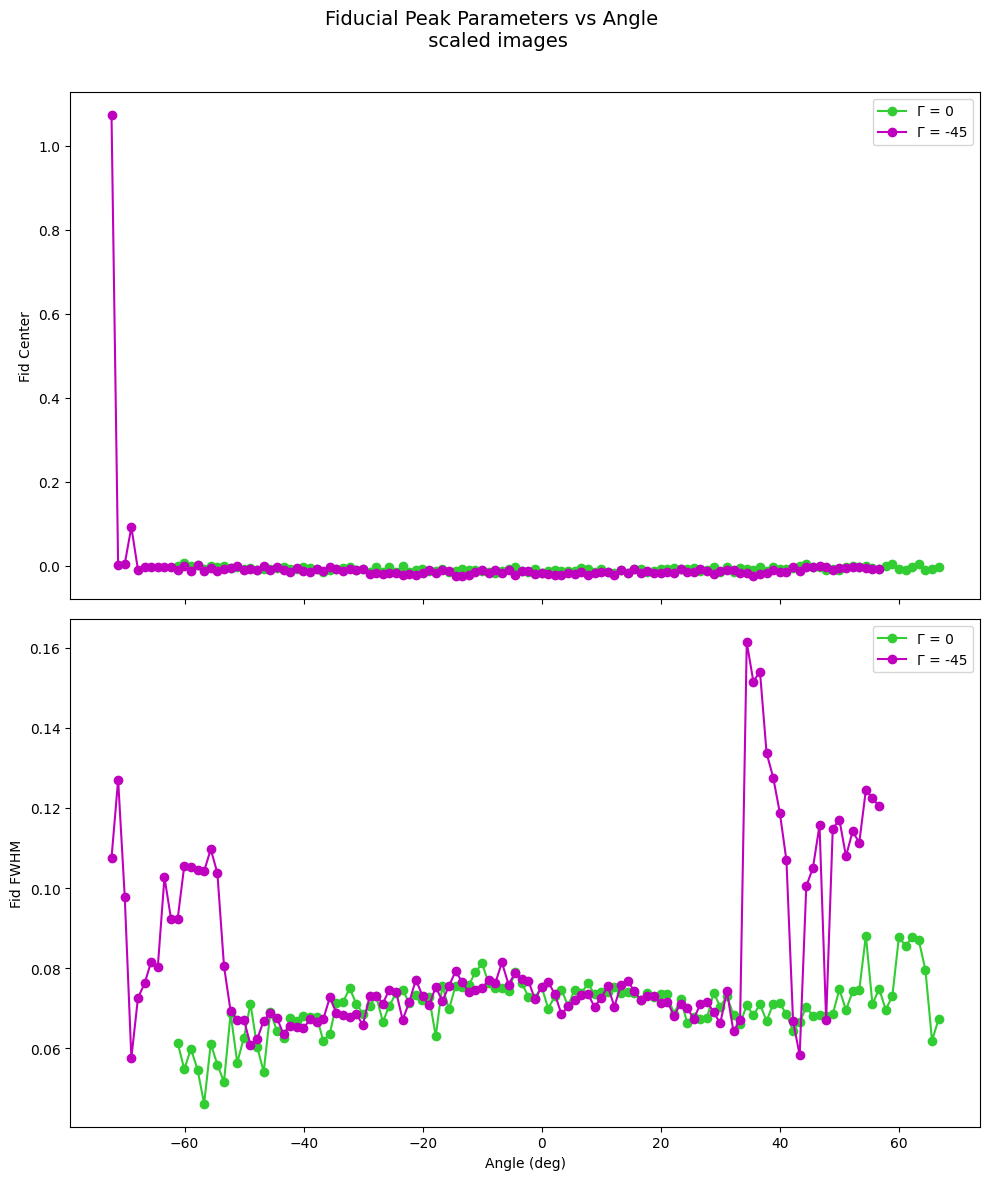

In [22]:
## plotting ##
fig, axes = plt.subplots(2, 1, figsize=(10, 12), sharex=True)

axes[0].plot(angles_0, CC_centers_0_scale, 'o-', label="Γ = 0", color = 'limegreen' )
axes[0].plot(angles_neg45, CC_centers_neg45_scale, 'o-', label="Γ = -45", color = 'm')
# axes[0].plot(angles_pos45, CC_centers_pos45, 'o-', label="Γ = +45", color = 'c')
axes[0].set_ylabel("CC Center", fontsize = '15')
# axes[0].set_ylim(1, 1.5)
axes[0].legend(fontsize = '15')

axes[1].plot(angles_0, CC_FWHMs_0_scale, 'o-', label="Γ = 0", color = 'limegreen' )
axes[1].plot(angles_neg45, CC_FWHMs_neg45_scale, 'o-', label="Γ = -45", color = 'm')
# axes[1].plot(angles_pos45, CC_FWHMs_pos45, 'o-', label="Γ = +45", color = 'orange')
axes[1].set_ylabel("CC FWHM", fontsize = '15')
# axes[1].set_ylim(0.1, 0.2)
axes[1].legend(fontsize = '15')
axes[1].set_xlabel("Angle (deg)", fontsize = '15')

fig.suptitle(f"Peak Parameters vs Angle \n scaled images", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(10, 12), sharex=True)
axes[0].plot(angles_0, fid_centers_0_scale, 'o-', label="Γ = 0", color = 'limegreen' )
axes[0].plot(angles_neg45, fid_centers_neg45_scale, 'o-', label="Γ = -45", color = 'm')
# axes[2].plot(angles_pos45, fid_centers_pos45, 'o-', label="Γ = +45", color = 'limegreen')
axes[0].set_ylabel("Fid Center")
axes[0].legend()

axes[1].plot(angles_0, fid_FWHMs_0_scale, 'o-', label="Γ = 0", color = 'limegreen' )
axes[1].plot(angles_neg45, fid_FWHMs_neg45_scale, 'o-', label="Γ = -45", color = 'm')
# axes[3].plot(angles_pos45, fid_FWHMs_pos45, 'o-', label="Γ = +45", color = 'm')
axes[1].set_ylabel("Fid FWHM")
axes[1].set_xlabel("Angle (deg)")
axes[1].legend()

fig.suptitle(f"Fiducial Peak Parameters vs Angle \n scaled images", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

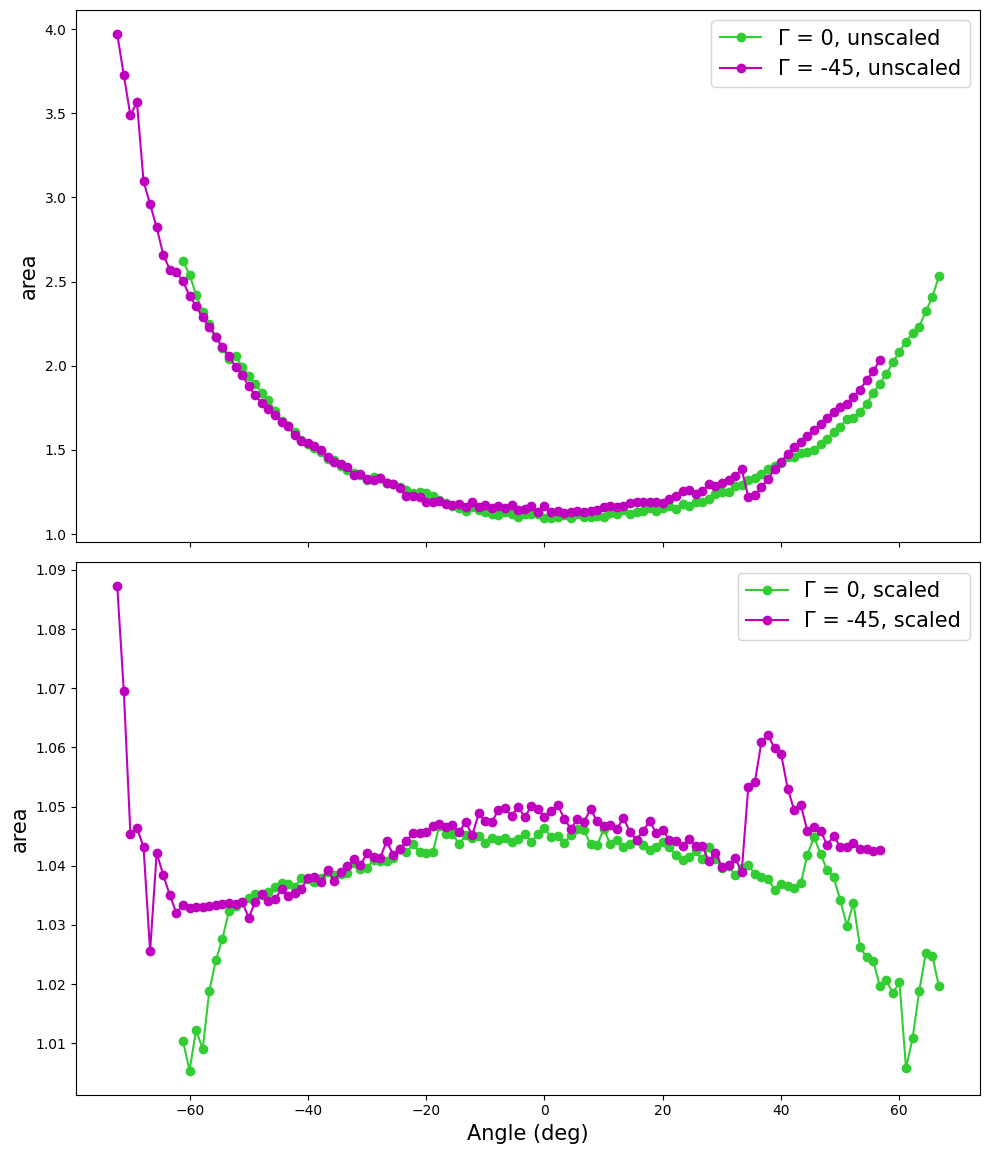

In [23]:
## area under the curves

## plotting FWHM and Centers for the unscaled images
fig, axes = plt.subplots(2, 1, figsize=(10, 12), sharex=True)

axes[0].plot(angles_0, CC_means_0_unscale, 'o-', label="Γ = 0, unscaled", color = 'limegreen' )
axes[0].plot(angles_neg45, CC_means_neg45_unscale, 'o-', label="Γ = -45, unscaled", color = 'm')
axes[0].set_ylabel("area", fontsize = '15')
# axes[0].set_ylim(1, 1.5)
axes[0].legend(fontsize = '15')

axes[1].plot(angles_0, CC_means_0_scale, 'o-', label="Γ = 0, scaled", color = 'limegreen' )
axes[1].plot(angles_neg45, CC_means_neg45_scale, 'o-', label="Γ = -45, scaled", color = 'm')
axes[1].set_ylabel("area", fontsize = '15')
# axes[1].set_ylim(0.1, 0.2)
axes[1].legend(fontsize = '15')
axes[1].set_xlabel("Angle (deg)", fontsize = '15')

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [24]:
stop

NameError: name 'stop' is not defined

# Compare Gamma +45 n = 20, n= 50

In [ ]:
color_neg = 'blue'
color_pos = 'orange'

norm = mpl.colors.Normalize(vmin=-0.2, vmax=0.2)


############ Gamma +45, n = 50
k = 49
angle = pos_angles_pos45[k]
# print(angle)

## normalize left and right to average intensity of the fiducials 
norm_neg_pos45, fid_avg_neg = auto_normalize_by_fiducial(image_stack_pospol_pos45[k], color_neg)
norm_pos_pos45, fid_avg_pos = auto_normalize_by_fiducial(image_stack_negpol_pos45[k], color_pos)

# transition everything to OD
OD_img_pos_pos45 = -1*np.log(norm_pos_pos45)
OD_img_neg_pos45= -1*np.log(norm_neg_pos45)
                                                         
norm_CC_pos45 = CC_pos45[k]
norm_XMCD_pos45 = XMCD_pos45[k]

## Plot XMCD to see contrast a bit better, control norm above
fig_size = 3.5
fig, axes = plt.subplots(1, 1, figsize=(fig_size * 3, fig_size))
pos = axes.imshow(norm_XMCD_pos45, norm=norm)
axes.set_title(f"Gamma +45 @ {angle:.2f} \n n = 50") 
fig.colorbar(pos)
plt.show()


############ Gamma +45, n = 20
k = 49
angle = pos_angles_pos45_20[k]
# print(angle)

## normalize left and right to average intensity of the fiducials 
norm_neg_pos45_20, fid_avg_neg = auto_normalize_by_fiducial(image_stack_pospol_pos45_20[k], color_neg)
norm_pos_pos45_20, fid_avg_pos = auto_normalize_by_fiducial(image_stack_negpol_pos45_20[k], color_pos)

# transition everything to OD
OD_img_pos_pos45_20 = -1*np.log(norm_pos_pos45_20)
OD_img_neg_pos45_20 = -1*np.log(norm_neg_pos45_20)
                                                         
norm_CC_pos45_20 = CC_pos45_20[k]
norm_XMCD_pos45_20 = XMCD_pos45_20[k]

## Plot XMCD to see contrast a bit better, control norm above
fig_size = 3.5
fig, axes = plt.subplots(1, 1, figsize=(fig_size * 3, fig_size))
pos = axes.imshow(norm_XMCD_pos45_20, norm=norm)
axes.set_title(f"Gamma +45 @ {angle:.2f} \n n = 20") 
fig.colorbar(pos)
plt.show()

In [ ]:
## Plot CPL
title = f'Normalized CPL \n {angle:.2f} deg'
vals_CC_0 = OD_img_neg_pos45.flatten()
vals_CC_0_20 = OD_img_neg_pos45_20.flatten()

plt.hist(vals_CC_0, bins = 100, alpha = 0.8, color = 'orange', label = 'Gamma = +45 , n = 50')
plt.hist(vals_CC_0_20, bins = 100, alpha = 0.5, color = 'hotpink', label = 'Gamma = +45 , n = 20')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
plt.xlim(-0.25, 0.25)
plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

## Plot XMCD
title = f'Normalized& Aligned XMCD \n {angle:.2f} deg'
vals_CC_0 = norm_XMCD_pos45.flatten()
vals_CC_0_20 = norm_XMCD_pos45_20.flatten()

plt.hist(vals_CC_0, bins = 100, alpha = 0.8, color = 'orange', label = 'Gamma = +45 , n = 50')
plt.hist(vals_CC_0_20, bins = 100, alpha = 0.5, color = 'hotpink', label = 'Gamma = +45 , n = 20')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

## Plot CC
title = f'Normalized & Aligned CC \n {angle:.2f} deg'
vals_CC_0 = norm_CC_pos45.flatten()
vals_CC_0_20 = norm_CC_pos45_20.flatten()

plt.hist(vals_CC_0, bins = 100, alpha = 0.8, color = 'orange', label = 'Gamma = +45 , n = 50')
plt.hist(vals_CC_0_20, bins = 100, alpha = 0.5, color = 'hotpink', label = 'Gamma = +45 , n = 20')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
plt.xlim(-0.25, 0.25)
plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

# Compare Gamma 0 n = 20 and n =  50

In [ ]:
color_neg = 'blue'
color_pos = 'orange'

norm = mpl.colors.Normalize(vmin=-0.2, vmax=0.2)


############ Gamma 0, n = 50
k = 10
angle = pos_angles_0[k]
# print(angle)

## normalize left and right to average intensity of the fiducials 
norm_neg_0, fid_avg_neg = auto_normalize_by_fiducial(image_stack_negpol_0[k], color_neg)
norm_pos_0, fid_avg_pos = auto_normalize_by_fiducial(image_stack_pospol_0[k], color_pos)

OD_img_pos_0 = -1*np.log(norm_neg_0)
OD_img_neg_0 = -1*np.log(norm_pos_0)

norm_CC_0 = CC_0[k]
norm_XMCD_0 = XMCD_0[k]

## Plot XMCD to see contrast a bit better, control norm above
fig_size = 3.5
fig, axes = plt.subplots(1, 1, figsize=(fig_size * 3, fig_size))
pos = axes.imshow(norm_XMCD_0, norm=norm)
axes.set_title(f"Gamma 0 @ {angle:.2f} \n n = 50") 
fig.colorbar(pos)
plt.show()


############ Gamma 0, n = 20
k = 10
angle = pos_angles_0_20[k]
# print(angle)

## normalize left and right to average intensity of the fiducials 
norm_neg_0_20, fid_avg_neg = auto_normalize_by_fiducial(image_stack_negpol_0_20[k], color_neg)
norm_pos_0_20, fid_avg_pos = auto_normalize_by_fiducial(image_stack_pospol_0_20[k], color_pos)

OD_img_pos_0_20 = -1*np.log(norm_neg_0_20)
OD_img_neg_0_20 = -1*np.log(norm_pos_0_20)

norm_CC_0_20 = CC_0_20[k]
norm_XMCD_0_20 = XMCD_0_20[k]

## Plot XMCD to see contrast a bit better, control norm above
fig_size = 3.5
fig, axes = plt.subplots(1, 1, figsize=(fig_size * 3, fig_size))
pos = axes.imshow(norm_XMCD_0_20, norm=norm)
axes.set_title(f"Gamma 0 @ {angle:.2f} \n n = 20") 
fig.colorbar(pos)
plt.show()


In [ ]:
## Plot CPL
title = f'Normalized CPL \n {angle:.2f} deg'
vals_CC_0 = OD_img_neg_0.flatten()
vals_CC_0_20 = OD_img_neg_0_20.flatten()

plt.hist(vals_CC_0, bins = 100, alpha = 0.8, color = 'green', label = 'Gamma = 0 , n = 50')
plt.hist(vals_CC_0_20, bins = 100, alpha = 0.5, color = 'purple', label = 'Gamma = 0 , n = 20')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

## Plot XMCD
title = f'Normalized& Aligned XMCD \n {angle:.2f} deg'
vals_CC_0 = norm_XMCD_0.flatten()
vals_CC_0_20 = norm_XMCD_0_20.flatten()

plt.hist(vals_CC_0, bins = 100, alpha = 0.8, color = 'green', label = 'Gamma = 0 , n = 50')
plt.hist(vals_CC_0_20, bins = 100, alpha = 0.5, color = 'purple', label = 'Gamma = 0 , n = 20')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

## Plot CC
title = f'Normalized & Aligned CC \n {angle:.2f} deg'
vals_CC_0 = norm_CC_0.flatten()
vals_CC_0_20 = norm_CC_0_20.flatten()

plt.hist(vals_CC_0, bins = 100, alpha = 0.8, color = 'green', label = 'Gamma = 0 , n = 50')
plt.hist(vals_CC_0_20, bins = 100, alpha = 0.5, color = 'purple', label = 'Gamma = 0 , n = 20')

plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
# plt.xlim(-0.25, 0.25)
# plt.ylim(0, 1500)
plt.legend()
plt.title(f'{title}')
plt.show()

In [ ]:
pos_angles_0.shape

In [ ]:
stop

1. Creates a mask based on the average intensity of the holes and normalizes incoming intensity to 1
2. Performs cross correlation of the fiducials over a range of 10 pixels
3. translates the negative polarity image
4. XMCD = translated left - right
5. CC = translated left + right 


In [ ]:
# ## Look at a single scan, select k
# plt.rcParams['font.family'] = ['Times New Roman', 'serif']

## Select which image to look at 
k = 43
angle = angles_pospol[k]


## Plot left, right, and charge contrast 
norm = mpl.colors.Normalize(vmin=0, vmax=3)
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
left = axes[0].imshow(image_stack_negpol[k], norm=norm)
#axes[0].set_title(f" {Gamma} Left polarization @ {angle:.2f} \n unnormalized") 
axes[0].set_title(f" Left polarization \n Γ = -45, α = {angle:.2f}", fontsize=14) 
fig.colorbar(left)
right = axes[1].imshow(image_stack_pospol[k], norm=norm)
#axes[1].set_title(f"{Gamma} Right polarization @ {angle:.2f} \n unnormalized")
axes[1].set_title(f" Right polarization \n Γ = -45, α = {angle:.2f}",  fontsize=14)
fig.colorbar(right)
plt.show()

## Plot masked left and right scans
norm = mpl.colors.Normalize(vmin=0, vmax=3)
fig_size = 3.5
fig, axes = plt.subplots(1, 1, figsize=(fig_size * 3, fig_size))
pos = axes.imshow(image_stack_negpol[k] + image_stack_pospol[k], norm=norm)
axes.set_title(f"{Gamma} positive @ {angle:.2f} \n CC") 
fig.colorbar(pos)
plt.show()


## Plot original histogram of left and right
title = 'Un-normalized'
color_neg = 'blue'
color_pos = 'orange'
vals_neg = image_stack_negpol[k].flatten()
vals_pos = image_stack_pospol[k].flatten()
plot_histogram(vals_neg, vals_pos, color_neg, color_pos)

## normalize left and right to average intensity of the fiducials 
norm_neg, fid_avg_neg = auto_normalize_by_fiducial(image_stack_negpol[k], color_neg)
norm_pos, fid_avg_pos = auto_normalize_by_fiducial(image_stack_pospol[k], color_pos)

print(f'norm_neg = {norm_neg}')
print(f'norm_pos = {norm_pos}')

## Plot left, right, and charge contrast 
norm = mpl.colors.Normalize(vmin=-2, vmax=2)
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
left = axes[0].imshow(-1*np.log(norm_neg), norm=norm)
#axes[0].set_title(f" {Gamma} Left polarization @ {angle:.2f} \n unnormalized") 
axes[0].set_title(f"Log Left polarization \n Γ = 0, α = {angle:.2f}", fontsize=14) 
fig.colorbar(left)
right = axes[1].imshow(-1*np.log(norm_pos), norm=norm)
#axes[1].set_title(f"{Gamma} Right polarization @ {angle:.2f} \n unnormalized")
axes[1].set_title(f" Log Right polarization \n Γ = 0, α = {angle:.2f}",  fontsize=14)
fig.colorbar(right)
plt.show()

## Plot normalized histogram left and right
title = 'Normalized'
vals_neg = norm_neg.flatten()
vals_pos = norm_pos.flatten()
plot_histogram(vals_neg, vals_pos, color_neg, color_pos)

## apply a mask to 30% of hole intenstity 
factor = 0.7 #30%
masked_pos, masked_neg = mask_holes_to_one(norm_pos,norm_neg, factor)

## Plot masked left and right scans
norm = mpl.colors.Normalize(vmin=-0.01, vmax=0.01)
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
pos = axes[0].imshow(masked_pos, norm=norm)
axes[0].set_title(f"{Gamma} positive @ {angle:.2f} \n masked") 
fig.colorbar(pos)
neg = axes[1].imshow(masked_neg, norm=norm)
axes[1].set_title(f"{Gamma} negative @ {angle:.2f} \n masked")
fig.colorbar(neg)
plt.show()


## Perform crosscorrelation on normalized/masked values
bound = 6 ## Add if statements later on for scans that need larger bounds
translation, corr = align_images_CC(masked_pos, masked_neg, bound)
print(f"Estimated Translation = {translation}")

## Translating the Negative Image
f_target = fftn(norm_neg)
f_target_shifted = fourier_shift(f_target, translation)
translated_negpol = ifftn(f_target_shifted).real

## Translating the phase image by the same amount
f_target = fftn(phase_stack_negpol[k])
f_target_shifted = fourier_shift(f_target, translation)
translated_negpol_phase = ifftn(f_target_shifted).real

unaligned_diffMap = -1*np.log(norm_neg) - -1*np.log(norm_pos)
aligned_diffMap = -1*np.log(translated_negpol) - -1*np.log(norm_pos)

plot_XMCD_crosscorr(unaligned_diffMap, aligned_diffMap, corr)

## Plot masked left and right scans
norm = mpl.colors.Normalize(vmin=2, vmax=3)
fig_size = 3.5
fig, axes = plt.subplots(1, 1, figsize=(fig_size * 3, fig_size))
pos = axes.imshow(-1*np.log(translated_negpol) + -1*np.log(norm_pos), norm=norm)
axes.set_title(f"{Gamma} positive @ {angle:.2f} \n CC") 
fig.colorbar(pos)
plt.show()


    

In [ ]:
# ## Look at a single scan, select k
# plt.rcParams['font.family'] = ['Times New Roman', 'serif']

## Select which image to look at 
k = 42
angle = angles_pospol[k]

# transition everything to OD
OD_img_pos = -1*np.log(image_stack_negpol[k])
OD_img_neg = -1*np.log(image_stack_pospol[k])

## Plot left, right OD un-normalized
norm = mpl.colors.Normalize(vmin=-1, vmax=1)
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
left = axes[0].imshow(OD_img_neg, norm=norm)
#axes[0].set_title(f" {Gamma} Left polarization @ {angle:.2f} \n unnormalized") 
axes[0].set_title(f" Left polarization \n {Gamma}, α = {angle:.2f}", fontsize=14) 
fig.colorbar(left)
right = axes[1].imshow(OD_img_pos, norm=norm)
#axes[1].set_title(f"{Gamma} Right polarization @ {angle:.2f} \n unnormalized")
axes[1].set_title(f" Right polarization \n {Gamma}, α = {angle:.2f}",  fontsize=14)
fig.colorbar(right)
plt.show()

## CC
norm = mpl.colors.Normalize(vmin=-1, vmax=1)
fig_size = 3.5
fig, axes = plt.subplots(1, 1, figsize=(fig_size * 3, fig_size))
pos = axes.imshow(OD_img_pos + OD_img_neg, norm=norm)
axes.set_title(f"{Gamma} positive @ {angle:.2f} \n CC") 
fig.colorbar(pos)
plt.show()


## Plot original histogram of left and right
title = 'Un-normalized'
color_neg = 'blue'
color_pos = 'orange'
vals_neg = OD_img_neg.flatten()
vals_pos = OD_img_pos.flatten()
plot_histogram(vals_neg, vals_pos, color_neg, color_pos)

###################################### Normalized

## normalize left and right to average intensity of the fiducials 
norm_neg, fid_avg_neg = auto_normalize_by_fiducial(OD_img_neg, color_neg)
norm_pos, fid_avg_pos = auto_normalize_by_fiducial(OD_img_pos, color_pos)

## Plot left, right, and charge contrast 
norm = mpl.colors.Normalize(vmin=-2, vmax=2)
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
left = axes[0].imshow((norm_neg), norm=norm)
#axes[0].set_title(f" {Gamma} Left polarization @ {angle:.2f} \n unnormalized") 
axes[0].set_title(f"Normalized Left polarization \n {Gamma}, α = {angle:.2f}", fontsize=14) 
fig.colorbar(left)
right = axes[1].imshow((norm_pos), norm=norm)
#axes[1].set_title(f"{Gamma} Right polarization @ {angle:.2f} \n unnormalized")
axes[1].set_title(f" Normalized Right polarization \n {Gamma}, α = {angle:.2f}",  fontsize=14)
fig.colorbar(right)
plt.show()

## Plot normalized histogram left and right
title = 'Normalized'
vals_neg = norm_neg.flatten()
vals_pos = norm_pos.flatten()
plot_histogram(vals_neg, vals_pos, color_neg, color_pos)

norm_CC_neg45 = (norm_neg) + (norm_pos)
norm_XMCD_neg45 = (norm_neg - norm_pos)

## Plot left, right, and charge contrast 
norm = mpl.colors.Normalize(vmin=-2, vmax=2)
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
left = axes[0].imshow(norm_CC_neg45, norm=norm)
axes[0].set_title(f"Normalized CC \n {Gamma}, α = {angle:.2f}", fontsize=14) 
fig.colorbar(left)
right = axes[1].imshow(norm_XMCD_neg45, norm=norm)
axes[1].set_title(f" Normalized XMCD \n {Gamma}, α = {angle:.2f}",  fontsize=14)
fig.colorbar(right)
plt.show()


################################ Histograms of CC 

## Plot normalized histogram left and right
title = 'Normalized CC'
vals_CC_neg45 = norm_CC_neg45.flatten()

# plot_single_histogram(vals_CC_0, color_pos)


In [ ]:
## Plot normalized histogram left and right
title = 'Compare 0 and negative 45'
plot_histogram(vals_CC_neg45, vals_CC_0, color_neg, color_pos)

In [ ]:
stop

In [ ]:
for k in range(image_stack_pospol.shape[0]):
    angle = angles_pospol[k]
    plot_CLCR(-1*np.log(image_stack_negpol[k]), -1*np.log(image_stack_pospol[k]))
    # plot_CLCR((image_stack_negpol[k]), (image_stack_pospol[k]))

In [ ]:
## Background subtraction (SB)

## Select which image to look at 
k = 2
angle = angles_pospol[k]

## Fit background and plot
B_neg = fit_background(image_stack_negpol[k])
B_pos = fit_background(image_stack_pospol[k])

fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
left = axes[0].imshow(B_neg)
axes[0].set_title(f"{Gamma} Left polarization @ {angle:.2f} \n Background") 
fig.colorbar(left)
right = axes[1].imshow(B_pos)
axes[1].set_title(f"{Gamma} Right polarization @ {angle:.2f} \n Background")
fig.colorbar(right)
plt.show()

## Subtract background and plot
image_negsub = image_stack_negpol[k] - B_neg
image_possub = image_stack_pospol[k] - B_pos

norm = mpl.colors.Normalize(vmin=-1, vmax=1)
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
left = axes[0].imshow(image_negsub, norm=norm)
axes[0].set_title(f"{Gamma} Left polarization @ {angle:.2f} \n Background Subtracted") 
fig.colorbar(left)
right = axes[1].imshow(image_possub, norm=norm)
axes[1].set_title(f"{Gamma} Right polarization @ {angle:.2f} \n Background Subtracted")
fig.colorbar(right)
plt.show()

# Normalize to fiducials and plot histogram
color_neg = 'blue'
color_pos = 'orange'
neg_sb, fid_avg_neg_sb = auto_normalize_by_fiducial(image_negsub, color_neg)
pos_sb, fid_avg_pos_sb = auto_normalize_by_fiducial(image_possub, color_pos)
## Plot normalized histogram left and right
title = 'Background Subtracted'
vals_neg = neg_sb.flatten()
vals_pos = pos_sb.flatten()
plot_histogram(vals_neg, vals_pos, color_neg, color_pos)


# save tiff of XMCD and charge contrast

In [ ]:
stop

In [ ]:
date

In [ ]:
Gamma

In [ ]:
## Optical Density
tifffile.imwrite(os.path.join(data_dir, f"OD_negpol_aligned_stack{date}.tiff"), translated_negpol_final)

tifffile.imwrite(os.path.join(data_dir, f"OD_chrgcntrst_stack{date}_check_contrast.tiff"), CC_final)
tifffile.imwrite(os.path.join(data_dir, f"OD_XMCD_stack{date}_check_contras.tiff"), XMCD_final)

# tifffile.imwrite(os.path.join(data_dir, f"OD_chrgcntrst_log_stack{date}.tiff"), OD_chrgcntrst_log)
# tifffile.imwrite(os.path.join(data_dir, f"OD_XMCD_log_stack{date}.tiff"), OD_XMCD_log)

# tifffile.imwrite(os.path.join(data_dir, f"OD_chrgcntrst_sb_stack{date}_v2.tiff"), OD_chrgcntrst_subB)
# tifffile.imwrite(os.path.join(data_dir, f"OD_XMCD_sb_stack{date}_v2.tiff"), OD_XMCD_subB)

# ## Phase
# tifffile.imwrite(os.path.join(data_dir, f"phase_negpol_aligned_stack{date}_v2.tiff"), translated_negpol_phase)

# phase_chrgcntrst = phase_stack_pospol + translated_negpol_phase_final
# phase_XMCD = translated_negpol_phase_final - phase_stack_pospol

# tifffile.imwrite(os.path.join(data_dir, f"phase_chrgcntrst_stack{date}_v2.tiff"), phase_chrgcntrst)
# tifffile.imwrite(os.path.join(data_dir, f"phase_XMCD_stack{date}_v2.tiff"), phase_XMCD)

In [ ]:
stop